# Divorce Analysis — EDA and Preprocessing (3.1 and 3.2)

**Changes in Socioeconomic Characteristics Associated with Recent Divorce in the United States in 2008, 2016 & 2024**

Runs top to bottom without edits: it gets the raw IPUMS USA extract, decodes it, explores it (3.1) and applies the preprocessing shown as **before → what we used → after** (3.2). Every table and figure is produced by the code.

| Requirement | Where |
|---|---|
| Load the data, overview | Part A, **3.1 · 1** |
| Data quality (missing values, duplicates) with notes | **3.1 · 1–2** |
| Key distributions and correlation heatmaps | **3.1 · 3–5** |
| Preprocessing | Part C: **3.2.1** missing values and outliers, **3.2.2** normalization and encoding, **3.2.3** feature selection, **3.2.4** PCA |

**Run it:** *Run all* in Colab, Kaggle or locally. The raw file is taken from `data/` (or next to the notebook) and otherwise downloaded from `DATA_URL` (setup cell). Packages: `requirements.txt`. Full run: about 6–8 GB RAM and 20 minutes. Quick test: `SAMPLE_EVERY = 20` and `SAVE_OUTPUTS = False` (writes nothing). With `SAVE_OUTPUTS = True` everything is saved in `report_outputs/`.

## Part A — Setup, data and decoding

In [41]:
import os, re, sys, time, shutil, subprocess, tempfile, textwrap, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False
IN_KAGGLE = os.path.exists("/kaggle/input")

# ---- data source (set once) -----------------------------------------------------------------------------------
DATA_FILE_NAME = "usa_00008.dat.gz"   # raw IPUMS file (an already decoded usa_00008_decoded.csv also works)
DATA_URL = ""                         # shared link or Google Drive file id; used only if the file is not found
XML_URL = "https://raw.githubusercontent.com/borodooovitsyn/divorce-analysis/main/usa_00008.xml"   # codebook, if missing
# ---- run options ----------------------------------------------------------------------------------------------
SAMPLE_EVERY = 1      # 1 = all rows (full run). For a quick test use 20 (every 20th row).
SAVE_OUTPUTS = True   # True = save the figures (PNG) and result tables in OUT_FOLDER. False = save nothing.
OUT_FOLDER = "report_outputs"   # separate folder for the figures and tables used in the report
# ---------------------------------------------------------------------------------------------------------------

WORK_DIR = Path("/content") if IN_COLAB else Path("/kaggle/working") if IN_KAGGLE else Path.cwd()
DATA_DIR = WORK_DIR / "data"
OUT_DIR = (WORK_DIR / OUT_FOLDER) if SAVE_OUTPUTS else Path(tempfile.mkdtemp(prefix="divorce_"))   # scratch folder, deleted at the end


def find(*names):
    dirs = [DATA_DIR, WORK_DIR, Path.cwd() / "data", Path.cwd()] + (list(Path("/kaggle/input").glob("*")) if IN_KAGGLE else [])
    return next((d / n for d in dirs for n in names if (d / n).exists()), None)


def download(url, dest):
    if "drive.google.com" in url or not url.startswith("http"):            # Google Drive: gdown handles large files
        try:
            import gdown
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
            import gdown
        gdown.download(output=str(dest), quiet=False, **({"url": url, "fuzzy": True} if url.startswith("http") else {"id": url}))
    else:
        urllib.request.urlretrieve(url, dest)
    assert Path(dest).exists() and Path(dest).stat().st_size > 0, f"download failed: {url}"
    return Path(dest)


DAT_FILE = find(DATA_FILE_NAME, "usa_00008.dat", "usa_00008.dat.gz", "usa_00008_decoded.csv", "usa_00008_decoded.csv.gz")
if DAT_FILE is None:
    if not DATA_URL:
        raise FileNotFoundError(f"Raw data not found. Put {DATA_FILE_NAME} in {DATA_DIR} or set DATA_URL above.")
    DATA_DIR.mkdir(exist_ok=True)
    DAT_FILE = download(DATA_URL, DATA_DIR / DATA_FILE_NAME)
XML_FILE = find("usa_00008.xml") or download(XML_URL, WORK_DIR / "usa_00008.xml")
IS_CSV = DAT_FILE.name.endswith((".csv", ".csv.gz"))
print(f"{'Colab' if IN_COLAB else 'Kaggle' if IN_KAGGLE else 'Local'} | pandas {pd.__version__} | data: {DAT_FILE.name} "
      f"({DAT_FILE.stat().st_size / 1024**2:,.0f} MB, {'decoded csv' if IS_CSV else 'raw fixed-width'}) | codebook: {XML_FILE.name}")

Local | pandas 3.1.0 | data: usa_00008_decoded.csv (3,710 MB, decoded csv) | codebook: usa_00008.xml


## Part B — 3.1 Exploratory Data Analysis

**Data:** IPUMS USA extract `usa_00008` (ACS 2008, 2016, 2024), decoded directly from the raw IPUMS file in Part A of this notebook.

**Target:** `DIVINYR` – *divorced in the past year* (`Yes` vs `Blank (No)`).
It is only defined for its universe (people aged 15+ who have ever married), so
rows with `N/A` / `Suppressed` are not in scope for modelling.

The EDA is organised around the questions that drive preprocessing in 3.2:

| Section | What we examine | Feeds into 3.2 |
|---|---|---|
| 1. Dataset overview | rows, columns, dtypes, duplicates | cleaning requirements |
| 2. Missing values | % missing per feature (incl. IPUMS N/A codes) | imputation vs removal |
| 3. Numeric distributions | histograms, box plots, skew, outliers | transforms, clipping, scaling |
| 4. Categorical distributions | frequencies, cardinality, rare levels | encoding strategy |
| 5. Correlations | Spearman heatmap, Cramér's V | redundant features |
| 6. Target relationships | divorce rate by feature | predictive signal, leakage |
| 7. Class balance | target distribution (weighted / unweighted) | imbalance handling |

Every problem found is appended to `issues`, summarised at the end (section 8).

In [42]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import union_categoricals
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------
FIG_DIR = OUT_DIR / "figures" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

TARGET_RAW = "DIVINYR_LABEL"
TARGET = "divorced"          # 1 = divorced in past year, 0 = not
TARGET_POS = "Yes"
TARGET_NEG = "Blank (No)"
WEIGHT = "PERWT"

# Numeric variables kept by clean_ipums_features.py
NUMERIC_COLS = [
    "AGE", "FAMSIZE", "NCHILD", "UHRSWORK", "YRMARR",
    "RENT", "VALUEH", "HHINCOME", "INCTOT", "FTOTINC",
    "INCWAGE", "INCEARN", "POVERTY",
]

# Categorical features (label versions) kept by clean_ipums_features.py.
# Selecting explicitly means the notebook also works on the decoded (uncleaned)
# file or a sample of it – any other columns are ignored.
CATEGORICAL_COLS = [
    "HHTYPE_LABEL", "REGION_LABEL", "STATEFIP_LABEL", "METRO_LABEL",
    "OWNERSHP_LABEL", "COUPLETYPE_LABEL", "SEX_LABEL", "MARST_LABEL",
    "MARRNO_LABEL", "DIVINYR_LABEL", "RACE_LABEL", "HISPAN_LABEL",
    "EDUC_LABEL", "EMPSTAT_LABEL", "LABFORCE_LABEL", "CLASSWKR_LABEL",
    "WKSWORK2_LABEL", "MIGRATE1_LABEL", "VEHICLES_LABEL",
]

# IPUMS codes that mean "N/A / not in universe / missing" for numeric
# variables (from usa_00008.xml + IPUMS codebook). These are not real values.
NUMERIC_NA_CODES = {
    "AGE": [999],
    "UHRSWORK": [0],                 # N/A (not working)
    "YRMARR": [0],                   # N/A (never married)
    "RENT": [0],                     # N/A (owners, GQ)
    "VALUEH": [9999998, 9999999],    # Missing / N/A (renters)
    "HHINCOME": [9999999],
    "INCTOT": [9999998, 9999999],
    "FTOTINC": [9999998, 9999999],
    "INCWAGE": [999998, 999999],
    "POVERTY": [0],                  # N/A (group quarters)
}

# Category labels that mean "missing / not applicable"
CATEGORICAL_NA_LABELS = {
    "", "N/A", "Missing", "Missing/blank", "Blank, missing", "Not Applicable",
    "Unknown", "Unknown/Illegible", "Illegible",
    "Unclassifiable (employment status unknown)",
    "HHTYPE could not be determined", "State not identified", "Not identified",
}

# Report-friendly plot style: one hue for single series, two for target classes
BLUE, ORANGE = "#2a78d6", "#eb6834"
CLASS_PALETTE = {0: BLUE, 1: ORANGE}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

issues = []  # (section, feature, problem, suggested action for 3.2)


def add_issue(section, feature, problem, action):
    issues.append({"section": section, "feature": feature,
                   "problem": problem, "action_3_2": action})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def weighted_rate(y, w):
    return np.average(y, weights=w) if len(y) else np.nan

### Decode the data

The raw fixed-width file is decoded with the IPUMS codebook (positions, implied decimals, value labels), only for the variables used, straight into memory. `SERIAL` and `PERNUM` are kept separately for the duplicate check.

In [43]:
import gzip
import xml.etree.ElementTree as ET
from pandas.api.types import union_categoricals


def parse_codebook(xml_file):
    """Position, implied decimals and value labels of every variable (IPUMS DDI codebook)."""
    root = ET.parse(xml_file).getroot()
    ns = {"ddi": "ddi:codebook:2_5"}
    variables = []
    for var in root.findall(".//ddi:dataDscr/ddi:var", ns):
        loc = var.find("ddi:location", ns)
        labels = {}
        for cat in var.findall("ddi:catgry", ns):
            v, l = cat.find("ddi:catValu", ns), cat.find("ddi:labl", ns)
            if v is None or v.text is None:
                continue
            labels[v.text.strip()] = l.text.strip() if l is not None and l.text else ""
        variables.append({"name": var.get("name"), "start": int(loc.get("StartPos")) - 1, "end": int(loc.get("EndPos")),
                          "decimals": int(var.get("dcml", "0")), "labels": labels})
    return variables


def open_dat(path):
    path = str(path)
    if path.endswith(".gz"):
        return gzip.open(path, "rt", encoding="ISO-8859-1")
    return open(path, "r", encoding="ISO-8859-1", buffering=1024 * 1024 * 16)


def field(arr, start, end):
    """Column slice of the fixed-width block as a stripped string array."""
    col = np.ascontiguousarray(arr[:, start:end]).view(f"S{end - start}").ravel()
    return np.char.strip(col.astype(str))


def decode_dat(dat_path, variables, numeric, labelled, id_cols, chunk_size=250_000, progress=True, every=1):
    """Decode only the wanted variables of the fixed-width file.
    numeric   : variable names kept as numbers (implied decimals applied)
    labelled  : categorical variable names -> <NAME>_LABEL text columns (unmapped code -> NaN)
    id_cols   : identifier variables kept in a separate frame
    every     : keep every N-th row only (1 = all rows)
    """
    by_name = {v["name"]: v for v in variables}
    order = [v["name"] for v in variables if v["name"] in set(numeric) | set(labelled) | set(id_cols) | {"YEAR"}]
    parts, id_parts, n = [], [], 0

    def process(lines):
        width = len(lines[0])
        if len(set(map(len, lines))) != 1:                      # ragged lines: pad to the widest
            width = max(map(len, lines)); lines = [l.ljust(width) for l in lines]
        arr = np.frombuffer("".join(lines).encode("latin-1"), dtype="S1").reshape(len(lines), width)
        data, ids = {}, {}
        for name in order:
            v = by_name[name]
            f = field(arr, v["start"], v["end"])
            if name == "YEAR":
                data["YEAR"] = pd.Series(pd.to_numeric(f, errors="coerce")).astype("Int64")
            elif name in id_cols:
                ids[name] = pd.to_numeric(f, errors="coerce")
            elif name in numeric:
                x = pd.to_numeric(f, errors="coerce").astype("float64")
                data[name] = x / 10 ** v["decimals"] if v["decimals"] else x
            if name in labelled:
                data[name + "_LABEL"] = pd.Series(f).map(v["labels"]).astype("category")
        return pd.DataFrame(data), pd.DataFrame(ids)

    with open_dat(dat_path) as fh:
        batch = []
        for line_no, line in enumerate(fh):
            if every > 1 and line_no % every:
                continue
            batch.append(line.rstrip("\r\n"))
            if len(batch) == chunk_size:
                d, i = process(batch); parts.append(d); id_parts.append(i); n += len(batch); batch = []
                if progress: print(f"  {n:,} rows decoded")
        if batch:
            d, i = process(batch); parts.append(d); id_parts.append(i); n += len(batch)
    label_cols = [c for c in parts[0].columns if c.endswith("_LABEL")]
    raw = pd.concat([p.drop(columns=label_cols) for p in parts], ignore_index=True)
    for c in label_cols:                                              # chunks may differ in categories
        raw[c] = union_categoricals([p[c] for p in parts], ignore_order=True)
    return raw, pd.concat(id_parts, ignore_index=True)


def read_decoded_csv(path, numeric, labelled, id_cols, every=1):
    """Read a DECODED IPUMS csv (one <NAME> column per variable plus <NAME>_LABEL for categorical variables).
    Gives the same result as decode_dat(): numeric columns, <NAME>_LABEL category columns and the identifiers."""
    header = pd.read_csv(path, nrows=0).columns.tolist()
    id_present = [c for c in id_cols if c in header]
    num = [c for c in numeric if c in header]
    labs = [c + "_LABEL" for c in labelled if c + "_LABEL" in header]
    dtypes = {c: "float64" for c in num + id_present}
    dtypes.update({c: "category" for c in labs})
    dtypes["YEAR"] = "Int64"
    skip = (lambda i: i > 0 and (i - 1) % every != 0) if every > 1 else None        # keep data rows 0, N, 2N, ...
    df = pd.read_csv(path, usecols=["YEAR"] + num + labs + id_present, dtype=dtypes,
                     keep_default_na=False, na_values=[""], skiprows=skip)
    ids = df[id_present].copy() if id_present else None
    return df.drop(columns=id_present), ids

In [44]:
variables = parse_codebook(XML_FILE)
names_in_file = {v["name"] for v in variables}
numeric_dec = [c for c in NUMERIC_COLS if c in names_in_file] + [WEIGHT]
labelled = [c[:-6] for c in CATEGORICAL_COLS if c.endswith("_LABEL") and c[:-6] in names_in_file]
t0 = time.time()
if IS_CSV:
    raw, ids = read_decoded_csv(DAT_FILE, numeric_dec, labelled, ["SERIAL", "PERNUM"], every=SAMPLE_EVERY)
else:
    raw, ids = decode_dat(DAT_FILE, variables, numeric_dec, labelled, ["SERIAL", "PERNUM"], every=SAMPLE_EVERY)
numeric_cols = [c for c in NUMERIC_COLS if c in raw.columns]
label_cols = [c for c in CATEGORICAL_COLS if c in raw.columns]
raw = raw[["YEAR", WEIGHT] + numeric_cols + label_cols]
print(f"Decoded {len(raw):,} rows x {raw.shape[1]} columns in {(time.time() - t0) / 60:.1f} min (SAMPLE_EVERY={SAMPLE_EVERY})")
raw.head()

Decoded 5,641,835 rows x 32 columns in 0.2 min (SAMPLE_EVERY=1)


,YEAR,PERWT,AGE,FAMSIZE,NCHILD,UHRSWORK,YRMARR,RENT,VALUEH,HHINCOME,INCTOT,FTOTINC,INCWAGE,INCEARN,POVERTY,HHTYPE_LABEL,REGION_LABEL,STATEFIP_LABEL,METRO_LABEL,OWNERSHP_LABEL,COUPLETYPE_LABEL,SEX_LABEL,MARST_LABEL,MARRNO_LABEL,DIVINYR_LABEL,RACE_LABEL,EDUC_LABEL,EMPSTAT_LABEL,LABFORCE_LABEL,CLASSWKR_LABEL,WKSWORK2_LABEL,MIGRATE1_LABEL
0,2008,55.0,37.0,4.0,2.0,40.0,1998.0,0.0,210000.0,58100.0,58100.0,58100.0,57000.0,57000.0,271.0,Married-couple family household,East South Central Div.,Alabama,In metropolitan area: Central/principal city s...,Owned or being bought (loan),NaN,Male,"Married, spouse present",Married once,Blank (No),Other Asian or Pacific Islander,5+ years of college,Employed,"Yes, in the labor force",Works for wages,50-52 weeks,Same house
1,2008,49.0,36.0,4.0,2.0,0.0,1998.0,0.0,210000.0,58100.0,0.0,58100.0,0.0,0.0,271.0,Married-couple family household,East South Central Div.,Alabama,In metropolitan area: Central/principal city s...,Owned or being bought (loan),NaN,Female,"Married, spouse present",Married once,Blank (No),Other Asian or Pacific Islander,4 years of college,Not in labor force,"No, not in the labor force",N/A,N/A,Same house
2,2008,109.0,30.0,2.0,0.0,40.0,2006.0,0.0,230000.0,125000.0,75000.0,125000.0,75000.0,75000.0,501.0,Married-couple family household,East South Central Div.,Alabama,In metropolitan area: Central/principal city s...,Owned or being bought (loan),NaN,Male,"Married, spouse present",Married once,Blank (No),White,5+ years of college,Employed,"Yes, in the labor force",Works for wages,50-52 weeks,Same house
3,2008,94.0,30.0,2.0,0.0,40.0,2006.0,0.0,230000.0,125000.0,50000.0,125000.0,50000.0,50000.0,501.0,Married-couple family household,East South Central Div.,Alabama,In metropolitan area: Central/principal city s...,Owned or being bought (loan),NaN,Female,"Married, spouse present",Married once,Blank (No),White,4 years of college,Employed,"Yes, in the labor force",Works for wages,50-52 weeks,Same house
4,2008,101.0,40.0,3.0,2.0,40.0,2001.0,0.0,113000.0,50000.0,50000.0,50000.0,50000.0,50000.0,294.0,"Female householder, no husband present",East South Central Div.,Alabama,In metropolitan area: Central/principal city s...,Owned or being bought (loan),NaN,Female,Separated,Married once,Blank (No),Black/African American,2 years of college,Employed,"Yes, in the labor force",Works for wages,50-52 weeks,Same house


## 1. Dataset overview
Rows, columns, data types, memory and duplicates.

In [45]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
})
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}   "
      f"Memory: {raw.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
overview

Rows: 5,641,835   Columns: 32   Memory: 743 MB


,dtype,n_unique,example
YEAR,Int64,3,2008
PERWT,float64,1260,55.0
AGE,float64,79,37.0
FAMSIZE,float64,20,4.0
NCHILD,float64,10,2.0
UHRSWORK,float64,100,40.0
YRMARR,float64,97,1998.0
RENT,float64,165,0.0
VALUEH,float64,2596,210000.0
HHINCOME,float64,50785,58100.0


In [46]:
print("Rows per survey year:")
display(raw["YEAR"].value_counts().sort_index().to_frame("rows"))

# Constant columns carry no information
constant = [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1]
for c in constant:
    add_issue("1 Overview", c, "Constant column", "Drop")
print("Constant columns:", constant or "none")

Rows per survey year:


,rows
YEAR,
2008,1784054
2016,1844638
2024,2013143


Constant columns: none


In [47]:
# Duplicates. Household/person IDs were dropped during cleaning, so identical
# rows can be different people with the same profile – report, don't auto-drop.
n_dup = raw.duplicated().sum()
print(f"Fully duplicated rows: {n_dup:,} ({n_dup / len(raw):.2%})")
if n_dup:
    add_issue("1 Overview", "(all)",
              f"{n_dup:,} duplicate rows ({n_dup / len(raw):.2%}); IDs removed so "
              "these may be distinct people",
              "Keep (survey weights apply per person); verify with SERIAL/PERNUM if needed")

Fully duplicated rows: 746 (0.01%)


In [48]:
# Identifier check: (YEAR, SERIAL, PERNUM) identifies one person record, so it must be unique.
if ids is None or not {"SERIAL", "PERNUM"} <= set(ids.columns):
    n_key_dup = 0
    print("SERIAL / PERNUM are not in this file: the identifier check is skipped.")
else:
    n_key_dup = int(pd.DataFrame({"y": raw["YEAR"].astype(int), "s": ids["SERIAL"], "p": ids["PERNUM"]}).duplicated().sum())
    print(f"Records sharing the same (YEAR, SERIAL, PERNUM) key: {n_key_dup:,} ({n_key_dup / len(raw):.2%})")
if n_key_dup:
    add_issue("1 Overview", "(YEAR, SERIAL, PERNUM)", f"{n_key_dup:,} person records with a repeated identifier", "Inspect and drop the repeated records")

Records sharing the same (YEAR, SERIAL, PERNUM) key: 0 (0.00%)


**Notes — overview and duplicates:** _(write 2–3 lines: rows and years, the target universe, what the duplicate check shows)_

### Define the modelling universe and target
`DIVINYR` is `N/A` for people outside its universe (never married, under 15)
and `Suppressed` in some cases. Those rows cannot be labelled.

In [49]:
print(raw[TARGET_RAW].value_counts(dropna=False).to_frame("rows"))

df = raw[raw[TARGET_RAW].isin([TARGET_POS, TARGET_NEG])].copy()
df[TARGET] = (df[TARGET_RAW] == TARGET_POS).astype("int8")
df[TARGET_RAW] = df[TARGET_RAW].cat.remove_unused_categories()

out_of_universe = len(raw) - len(df)
print(f"\nIn target universe: {len(df):,} rows "
      f"({out_of_universe:,} rows dropped as N/A / Suppressed)")
add_issue("1 Overview", TARGET_RAW,
          f"{out_of_universe / len(raw):.1%} of rows have no target (N/A or Suppressed)",
          "Restrict modelling data to DIVINYR in {Yes, Blank (No)}")

# Everything below is analysed on the target universe
feature_label_cols = [c for c in label_cols if c != TARGET_RAW]

                  rows
DIVINYR_LABEL         
Blank (No)     5582088
Yes              59747

In target universe: 5,641,835 rows (0 rows dropped as N/A / Suppressed)


## 2. Missing values
Two kinds of missing in IPUMS:
* **true blanks** (empty cells), and
* **coded N/A** – sentinel numbers (e.g. `9999999`) or labels (`"N/A"`).
  Most of these are *structural* ("not in universe": renters have no house
  value, non-workers have no hours), which affects how we impute.

In [50]:
def missing_mask(frame):
    m = frame.isna()
    for c, codes in NUMERIC_NA_CODES.items():
        if c in frame:
            m[c] |= frame[c].isin(codes)
    for c in feature_label_cols:
        m[c] |= frame[c].astype(str).isin(CATEGORICAL_NA_LABELS)
    return m


miss = missing_mask(df)
missing_table = pd.DataFrame({
    "n_blank": df.isna().sum(),
    "n_missing_incl_NA_codes": miss.sum(),
    "blank_%": df.isna().mean() * 100,
    "missing_incl_NA_codes_%": miss.mean() * 100,
}).round(2).sort_values("missing_incl_NA_codes_%", ascending=False)
missing_table = missing_table[missing_table["missing_incl_NA_codes_%"] > 0]
missing_table.insert(0, "n_rows", len(df))

# Saved so 3.2 can report "before" counts when it imputes / removes.
# Note: nothing is removed or imputed in this notebook – df keeps every N/A.
missing_table.to_csv(FIG_DIR / "missing_values_before_preprocessing.csv")
missing_table

,n_rows,n_blank,n_missing_incl_NA_codes,blank_%,missing_incl_NA_codes_%
RENT,5641835,0,4655027,0.00,82.51
COUPLETYPE_LABEL,5641835,3628692,4142303,64.32,73.42
WKSWORK2_LABEL,5641835,0,2174067,0.00,38.53
UHRSWORK,5641835,0,2174067,0.00,38.53
CLASSWKR_LABEL,5641835,0,1653937,0.00,29.32
VALUEH,5641835,0,1208709,0.00,21.42
HHTYPE_LABEL,5641835,0,316813,0.00,5.62
POVERTY,5641835,0,138116,0.00,2.45
OWNERSHP_LABEL,5641835,0,138116,0.00,2.45
HHINCOME,5641835,0,138116,0.00,2.45


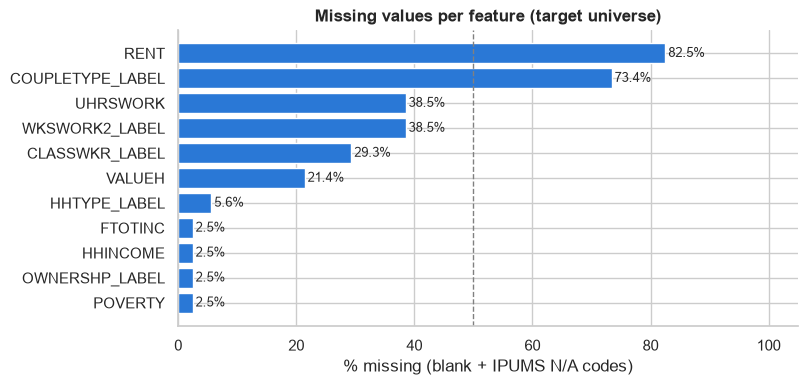

In [51]:
fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(missing_table))))
plot_data = missing_table["missing_incl_NA_codes_%"].sort_values()
ax.barh(plot_data.index, plot_data.values, color=BLUE)
for y, v in enumerate(plot_data.values):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9)
ax.axvline(50, color="grey", ls="--", lw=1)
ax.set_xlabel("% missing (blank + IPUMS N/A codes)")
ax.set_title("Missing values per feature (target universe)")
ax.set_xlim(0, 105)
save(fig, "02_missing_values")

In [52]:
# Is missingness related to the target? (informative missingness)
miss_vs_target = pd.DataFrame({
    "divorce_rate_if_missing_%": [df.loc[miss[c], TARGET].mean() * 100
                                  for c in missing_table.index],
    "divorce_rate_if_present_%": [df.loc[~miss[c], TARGET].mean() * 100
                                  for c in missing_table.index],
}, index=missing_table.index).round(2)
miss_vs_target

,divorce_rate_if_missing_%,divorce_rate_if_present_%
RENT,0.81,2.22
COUPLETYPE_LABEL,1.33,0.31
WKSWORK2_LABEL,0.58,1.36
UHRSWORK,0.58,1.36
CLASSWKR_LABEL,0.48,1.30
VALUEH,2.12,0.77
HHTYPE_LABEL,3.65,0.90
POVERTY,1.82,1.04
OWNERSHP_LABEL,1.82,1.04
HHINCOME,1.82,1.04


In [53]:
for c, pct in missing_table["missing_incl_NA_codes_%"].items():
    if pct >= 50:
        add_issue("2 Missing", c, f"{pct:.1f}% missing / N/A",
                  "Mostly structural N/A: drop, or encode as 0 + 'is_NA' flag")
    elif pct >= 5:
        add_issue("2 Missing", c, f"{pct:.1f}% missing / N/A",
                  "Impute (median / 'Missing' category) and add a missing-indicator")
    elif pct > 0:
        add_issue("2 Missing", c, f"{pct:.1f}% missing / N/A",
                  "Simple imputation or drop rows")

**Notes — missing values:** _(write 2–3 lines: which variables are mostly missing or not applicable, why, what it means for cleaning)_

## 3. Numeric feature distributions
IPUMS N/A codes are replaced by NaN first, otherwise e.g. `9999999` would
dominate the income distributions.

In [54]:
num = df[numeric_cols].copy()
for c, codes in NUMERIC_NA_CODES.items():
    if c in num:
        num[c] = num[c].mask(num[c].isin(codes))

desc = num.describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = num.skew()
desc["kurtosis"] = num.kurt()
desc["n_negative"] = (num < 0).sum()
desc["n_zero"] = (num == 0).sum()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,n_negative,n_zero
AGE,5641835.0,55.66,16.39,18.0,24.0,43.0,56.0,68.0,92.0,96.0,0.07,-0.72,0,0
FAMSIZE,5641835.0,2.74,1.48,1.0,1.0,2.0,2.0,4.0,7.0,20.0,1.38,3.32,0,0
NCHILD,5641835.0,0.76,1.09,0.0,0.0,0.0,0.0,1.0,4.0,9.0,1.61,3.17,0,3250997
UHRSWORK,3467768.0,39.52,12.64,1.0,4.0,38.0,40.0,45.0,76.0,99.0,-0.10,2.40,0,0
YRMARR,5641835.0,1989.88,18.46,1928.0,1946.0,1977.0,1992.0,2004.0,2023.0,2024.0,-0.37,-0.52,0,0
RENT,986808.0,1130.78,851.74,4.0,100.0,580.0,900.0,1500.0,4000.0,9400.0,2.60,13.08,0,0
VALUEH,4433126.0,377520.64,524186.65,0.0,7000.0,130000.0,250000.0,450000.0,2500000.0,9885000.0,6.68,70.15,0,466
HHINCOME,5503719.0,107602.18,112493.22,-39996.0,1800.0,42000.0,78000.0,132000.0,591000.0,3164000.0,3.66,23.34,1738,31947
INCTOT,5641835.0,51903.24,72697.30,-19998.0,0.0,13200.0,32700.0,63000.0,400000.0,1945000.0,4.75,35.13,5744,436236
FTOTINC,5503719.0,105865.40,111558.25,-39996.0,1300.0,40800.0,76500.0,130000.0,586500.0,3164000.0,3.63,22.62,1820,38851


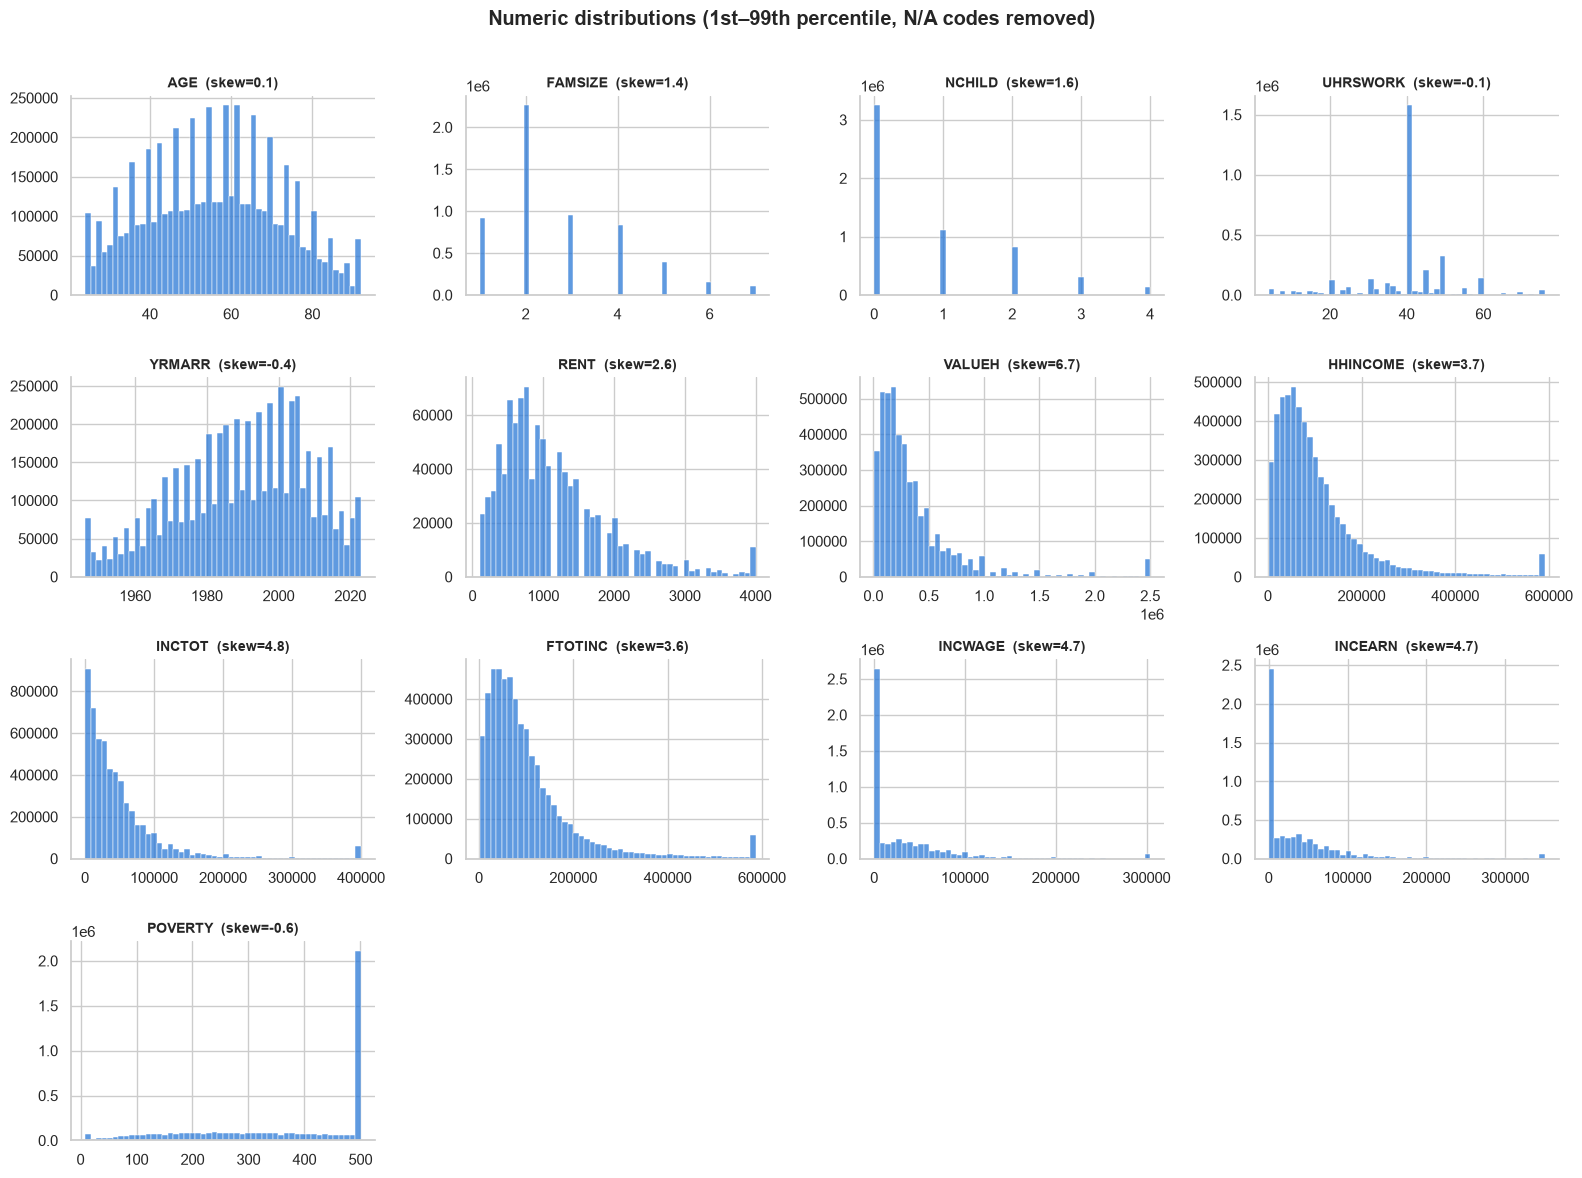

In [55]:
# Histograms – clipped to the 1st–99th percentile so the bulk is visible
ncols = 4
nrows = int(np.ceil(len(numeric_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
for ax, c in zip(axes.flat, numeric_cols):
    s = num[c].dropna()
    lo, hi = s.quantile([.01, .99])
    sns.histplot(s.clip(lo, hi), bins=50, ax=ax, color=BLUE, edgecolor="white")
    ax.set_title(f"{c}  (skew={s.skew():.1f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
fig.suptitle("Numeric distributions (1st–99th percentile, N/A codes removed)",
             fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "03_numeric_histograms")

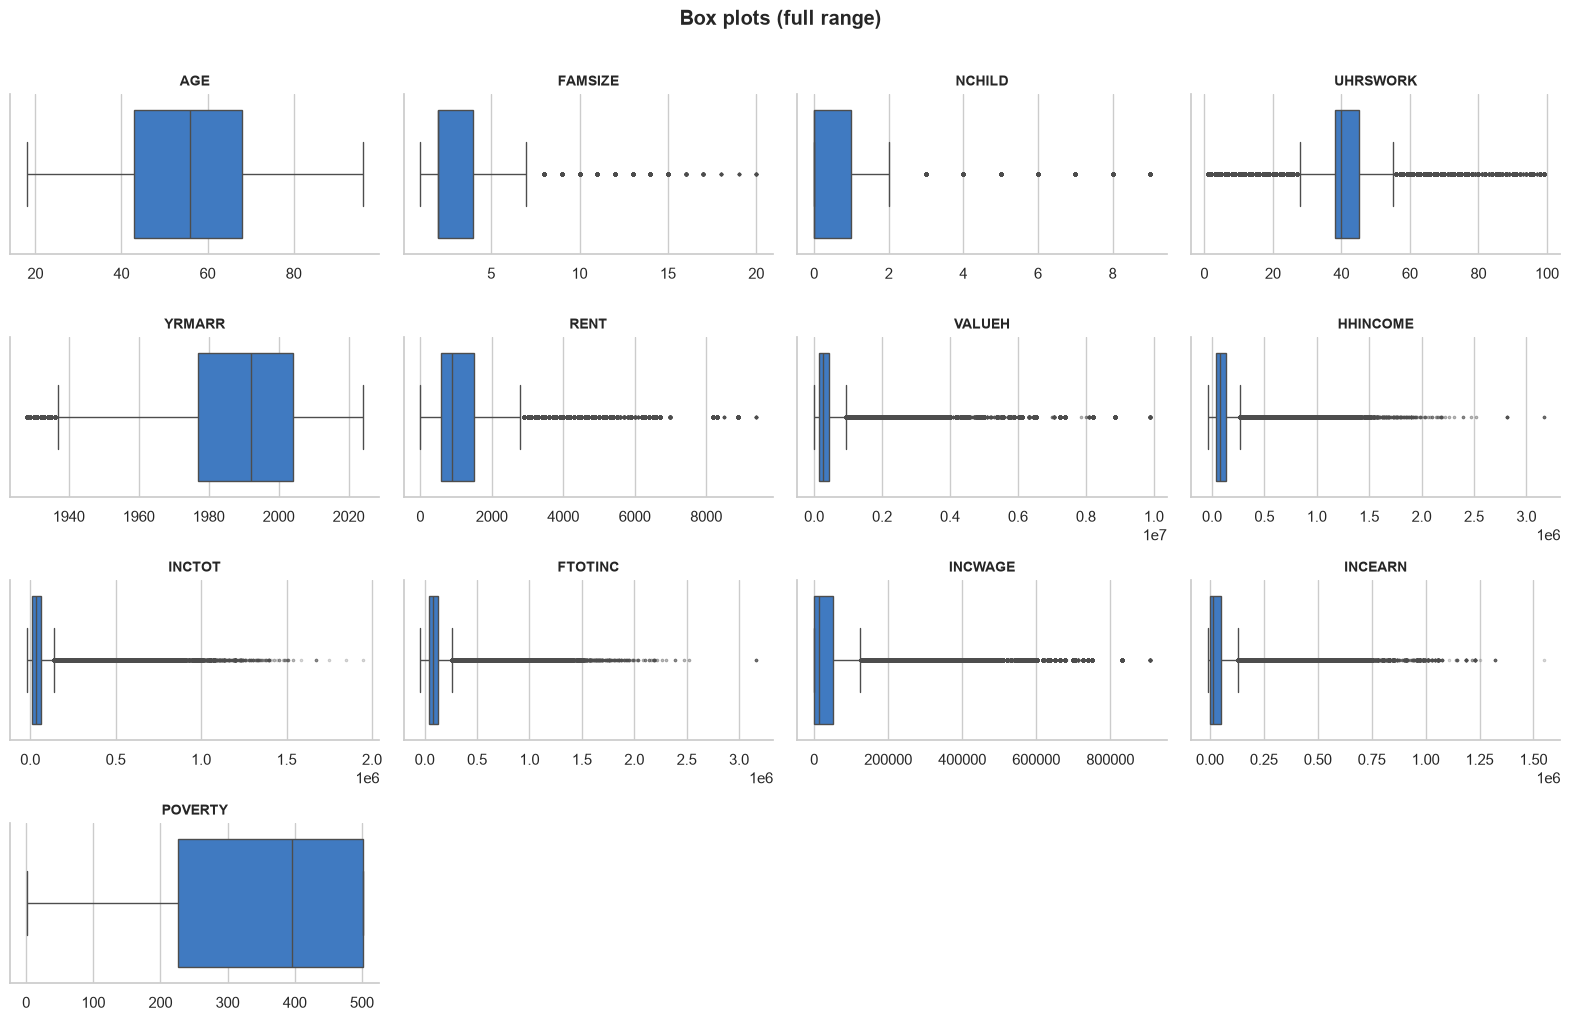

In [56]:
# Box plots on the full range – shows outliers and top-coding
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows))
for ax, c in zip(axes.flat, numeric_cols):
    sns.boxplot(x=num[c].dropna(), ax=ax, color=BLUE, fliersize=1.5,
                flierprops={"alpha": .3})
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
fig.suptitle("Box plots (full range)", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "03_numeric_boxplots")

In [57]:
# Outliers (IQR rule) and top-coding (many rows sitting exactly at the max)
rows = []
for c in numeric_cols:
    s = num[c].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    n_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    at_max = (s == s.max()).mean()
    rows.append({"feature": c, "IQR_outliers_%": 100 * n_out / len(s),
                 "share_at_max_%": 100 * at_max, "max": s.max(),
                 "skew": s.skew()})
outliers = pd.DataFrame(rows).set_index("feature").round(2)
outliers

,IQR_outliers_%,share_at_max_%,max,skew
feature,,,,
AGE,0.00,0.01,96.0,0.07
FAMSIZE,0.88,0.00,20.0,1.38
NCHILD,7.86,0.02,9.0,1.61
UHRSWORK,21.02,0.14,99.0,-0.10
YRMARR,0.07,0.35,2024.0,-0.37
RENT,4.02,0.00,9400.0,2.60
VALUEH,6.10,0.00,9885000.0,6.68
HHINCOME,6.32,0.00,3164000.0,3.66
INCTOT,6.61,0.00,1945000.0,4.75


In [58]:
for c, r in outliers.iterrows():
    if abs(r["skew"]) > 2:
        add_issue("3 Numeric", c, f"Strong skew ({r['skew']:.1f})",
                  "log1p / Yeo-Johnson transform (incomes may be negative)")
    if r["IQR_outliers_%"] > 5:
        add_issue("3 Numeric", c, f"{r['IQR_outliers_%']:.1f}% IQR outliers",
                  "Winsorise (e.g. 1st/99th pct) or use robust scaling")
    if r["share_at_max_%"] > 0.5 and r["max"] > 0:
        add_issue("3 Numeric", c,
                  f"{r['share_at_max_%']:.1f}% of rows at max ({r['max']:,.0f}) – top-coded",
                  "Treat max as censored; consider binning")
for c in numeric_cols:
    if desc.loc[c, "n_negative"] > 0:
        add_issue("3 Numeric", c, f"{int(desc.loc[c, 'n_negative']):,} negative values",
                  "Valid (business losses) – avoid plain log; use signed log / Yeo-Johnson")

# Incomes are in nominal dollars across 2008/2016/2024
add_issue("3 Numeric", "HHINCOME, INCTOT, FTOTINC, INCWAGE, INCEARN, RENT, VALUEH",
          "Nominal dollars across 2008/2016/2024 – not comparable over time",
          "Inflation-adjust to one year (CPI) or use within-year percentiles")

## 4. Categorical feature distributions
Cardinality and category frequencies decide the encoding (one-hot vs
ordinal vs target/frequency encoding) and which rare levels to merge.

In [59]:
cat_summary = pd.DataFrame({
    "n_categories": [df[c].nunique() for c in feature_label_cols],
    "top_category": [df[c].value_counts().index[0] for c in feature_label_cols],
    "top_share_%": [df[c].value_counts(normalize=True).iloc[0] * 100
                    for c in feature_label_cols],
    "n_rare_<1%": [(df[c].value_counts(normalize=True) < 0.01).sum()
                   for c in feature_label_cols],
}, index=feature_label_cols).round(2).sort_values("n_categories")
cat_summary

,n_categories,top_category,top_share_%,n_rare_<1%
SEX_LABEL,2,Female,53.85,0
LABFORCE_LABEL,2,"Yes, in the labor force",58.92,0
OWNERSHP_LABEL,3,Owned or being bought (loan),78.58,0
MARRNO_LABEL,3,Married once,74.68,0
EMPSTAT_LABEL,3,Employed,56.89,0
CLASSWKR_LABEL,3,Works for wages,61.65,0
MIGRATE1_LABEL,4,Same house,90.74,1
METRO_LABEL,5,In metropolitan area: Central/principal city s...,32.44,0
COUPLETYPE_LABEL,5,Opposite-sex husband/wife/spouse household,70.21,2
MARST_LABEL,5,"Married, spouse present",70.42,0


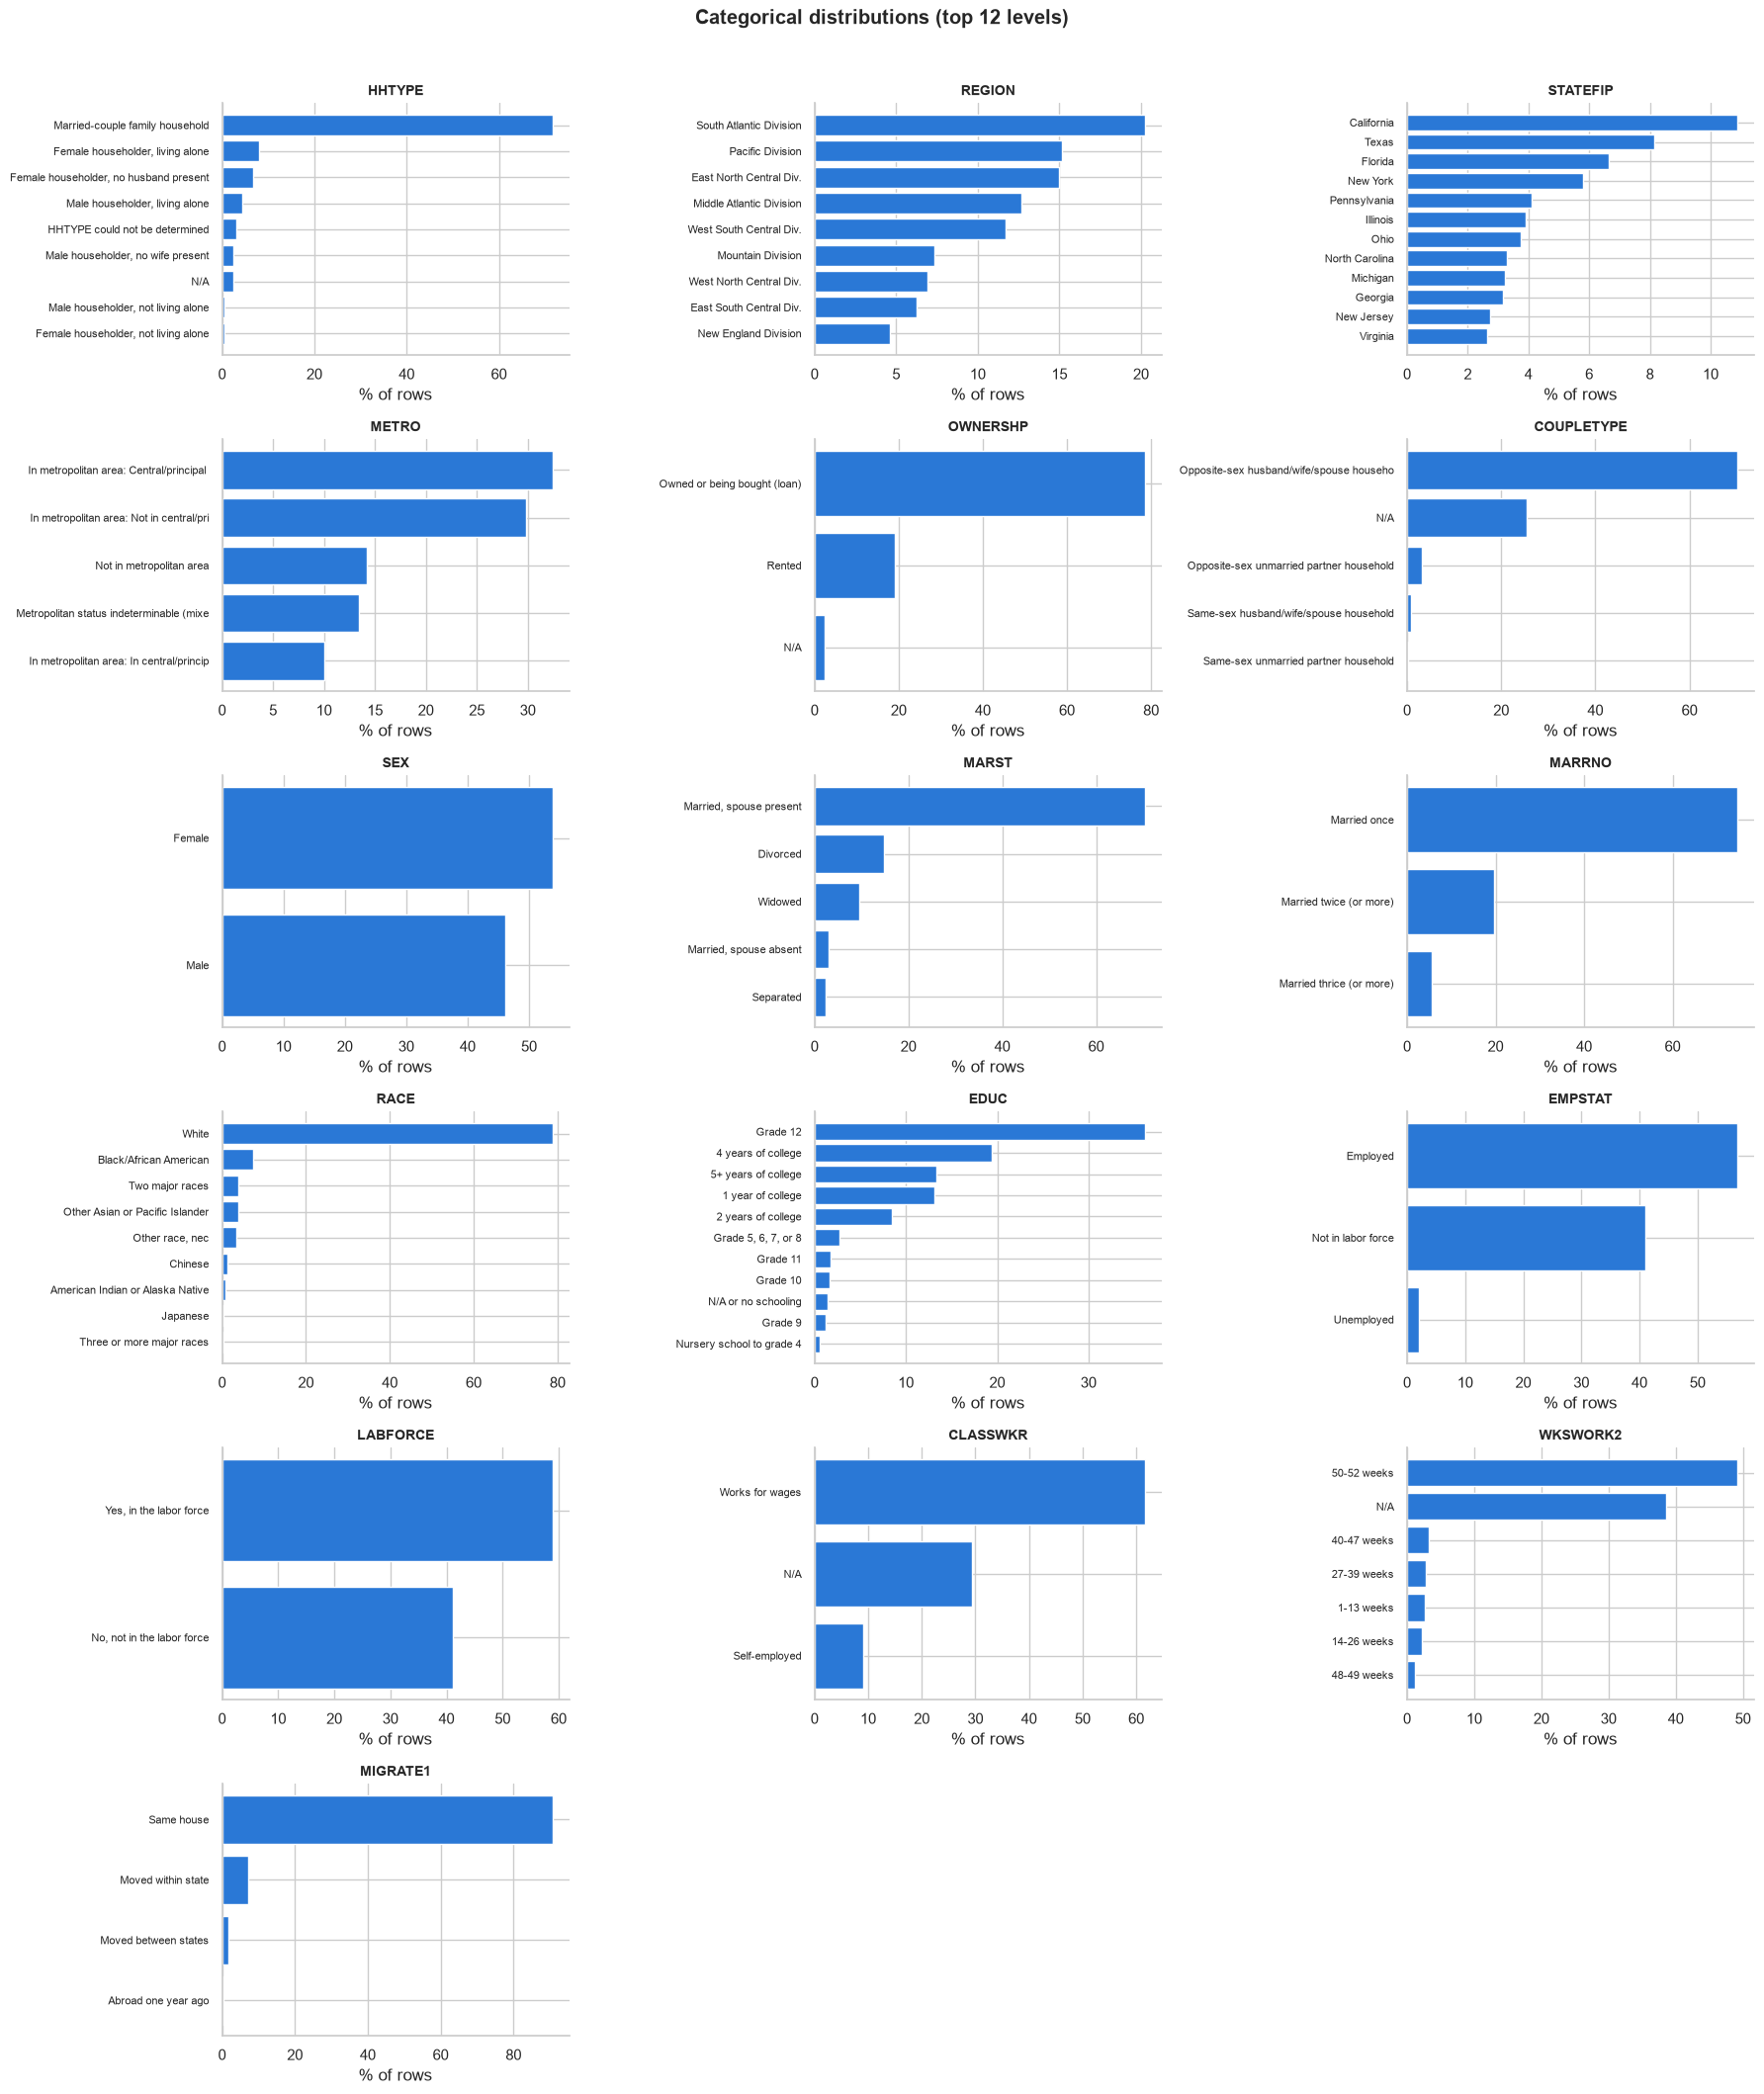

In [60]:
ncols = 3
nrows = int(np.ceil(len(feature_label_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, c in zip(axes.flat, feature_label_cols):
    vc = df[c].value_counts(normalize=True).head(12)[::-1] * 100
    ax.barh([str(i)[:40] for i in vc.index], vc.values, color=BLUE)
    ax.set_title(c.replace("_LABEL", ""), fontsize=10)
    ax.set_xlabel("% of rows")
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(feature_label_cols):]:
    ax.remove()
fig.suptitle("Categorical distributions (top 12 levels)", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "04_categorical_bars")

In [61]:
for c, r in cat_summary.iterrows():
    if r["n_categories"] > 15:
        add_issue("4 Categorical", c, f"High cardinality ({r['n_categories']} levels)",
                  "Target / frequency encoding, or group (e.g. state → region)")
    if r["n_rare_<1%"] > 0:
        add_issue("4 Categorical", c, f"{r['n_rare_<1%']} rare levels (<1%)",
                  "Merge rare levels into 'Other'")
    if r["top_share_%"] > 90:
        add_issue("4 Categorical", c, f"Near-constant ({r['top_share_%']:.1f}% one level)",
                  "Likely low value – consider dropping")

# Naturally ordered variables should be ordinal-encoded, not one-hot
add_issue("4 Categorical", "EDUC_LABEL, WKSWORK2_LABEL",
          "Ordered categories", "Ordinal encoding (preserve order)")

## 5. Correlations
* **Numeric:** Spearman (rank-based – robust to skew and outliers).
* **Categorical:** Cramér's V (association between two categoricals, 0–1).

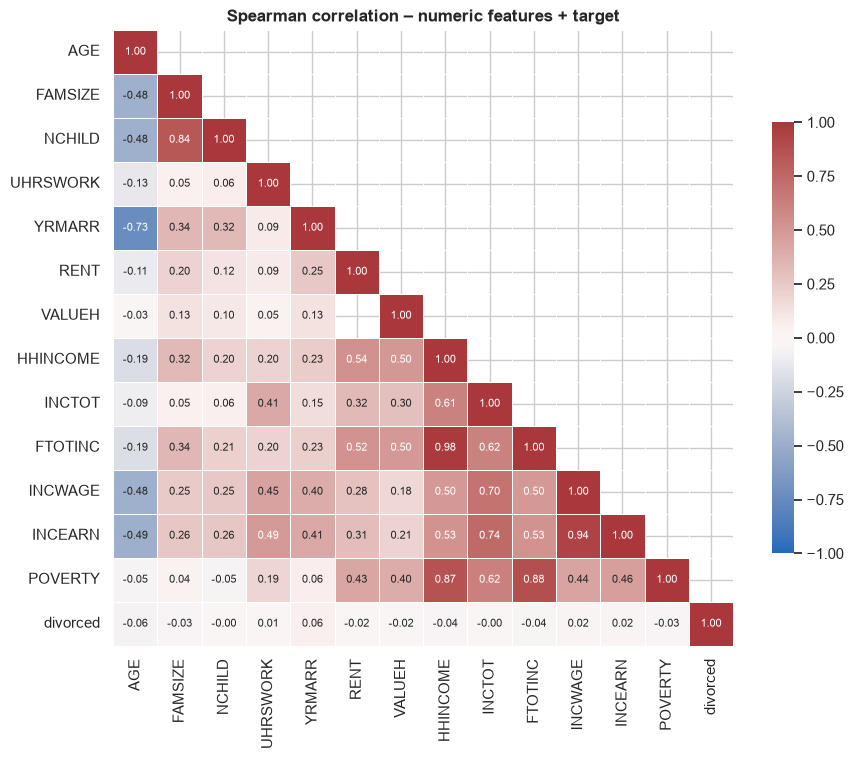

In [62]:
corr = num.assign(**{TARGET: df[TARGET]}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation – numeric features + target")
save(fig, "05_numeric_correlation")

In [63]:
high_corr = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
                 .stack().rename("rho").reset_index())
high_corr = high_corr[high_corr["rho"].abs() >= 0.8].sort_values(
    "rho", key=abs, ascending=False)
for _, r in high_corr.iterrows():
    add_issue("5 Correlation", f"{r['level_0']} ~ {r['level_1']}",
              f"Highly correlated (ρ={r['rho']:.2f})",
              "Keep one, combine, or reduce with PCA")
high_corr

,level_0,level_1,rho
107,HHINCOME,FTOTINC,0.983226
151,INCWAGE,INCEARN,0.944711
138,FTOTINC,POVERTY,0.882561
110,HHINCOME,POVERTY,0.866794
16,FAMSIZE,NCHILD,0.836987


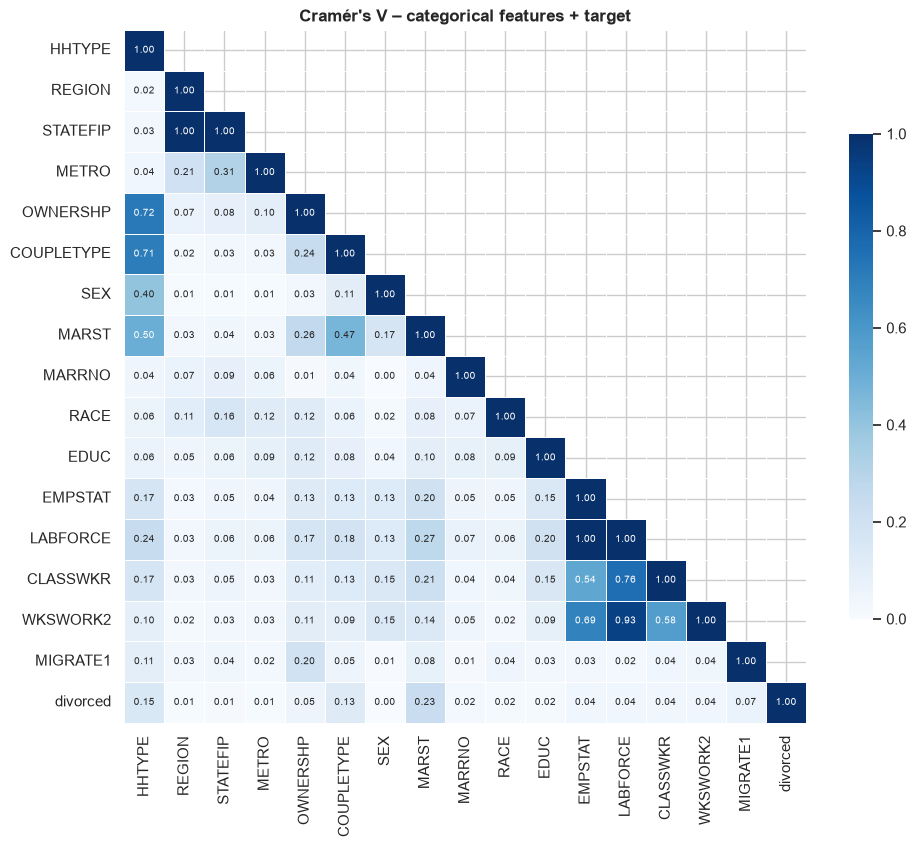

In [64]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


cv_cols = feature_label_cols + [TARGET]
cv = pd.DataFrame(np.eye(len(cv_cols)), index=cv_cols, columns=cv_cols)
for i, a in enumerate(cv_cols):
    for b in cv_cols[i + 1:]:
        cv.loc[a, b] = cv.loc[b, a] = cramers_v(df[a], df[b])
cv.index = cv.columns = [c.replace("_LABEL", "") for c in cv_cols]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cv, mask=np.triu(np.ones_like(cv, dtype=bool), k=1),
            cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Cramér's V – categorical features + target")
save(fig, "05_categorical_cramers_v")

In [65]:
cv_pairs = (cv.where(np.triu(np.ones_like(cv, dtype=bool), k=1))
              .stack().rename("cramers_v").reset_index())
cv_pairs = cv_pairs[cv_pairs["cramers_v"] >= 0.6].sort_values(
    "cramers_v", ascending=False)
for _, r in cv_pairs.iterrows():
    add_issue("5 Correlation", f"{r['level_0']} ~ {r['level_1']}",
              f"Strong association (Cramér's V={r['cramers_v']:.2f})",
              "Redundant – keep the more informative one")
cv_pairs

,level_0,level_1,cramers_v
19,REGION,STATEFIP,1.000000
199,EMPSTAT,LABFORCE,1.000000
218,LABFORCE,WKSWORK2,0.934606
217,LABFORCE,CLASSWKR,0.761374
4,HHTYPE,OWNERSHP,0.720587
5,HHTYPE,COUPLETYPE,0.706005
201,EMPSTAT,WKSWORK2,0.686604


**Notes — correlations:** _(write 2–3 lines: which feature pairs are almost duplicates and what that means for feature selection)_

## 6. Target relationships
Divorce rate by feature, **weighted by `PERWT`** so rates represent the US
population rather than the sample design.

In [66]:
# Divorce rate by survey year – the core research question
by_year = df.groupby("YEAR").apply(
    lambda g: pd.Series({"rows": len(g),
                         "divorces": g[TARGET].sum(),
                         "rate_unweighted_%": 100 * g[TARGET].mean(),
                         "rate_weighted_%": 100 * weighted_rate(g[TARGET], g[WEIGHT])}))
by_year.round(3)

,rows,divorces,rate_unweighted_%,rate_weighted_%
YEAR,,,,
2008,1784054.0,22428.0,1.257,1.496
2016,1844638.0,19600.0,1.063,1.217
2024,2013143.0,17719.0,0.880,1.026


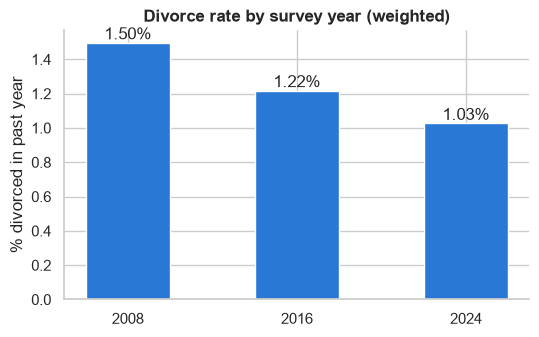

In [67]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_year.index.astype(str), by_year["rate_weighted_%"], color=BLUE, width=.5)
for x, v in enumerate(by_year["rate_weighted_%"]):
    ax.text(x, v, f"{v:.2f}%", ha="center", va="bottom")
ax.set_ylabel("% divorced in past year")
ax.set_title("Divorce rate by survey year (weighted)")
save(fig, "06_rate_by_year")

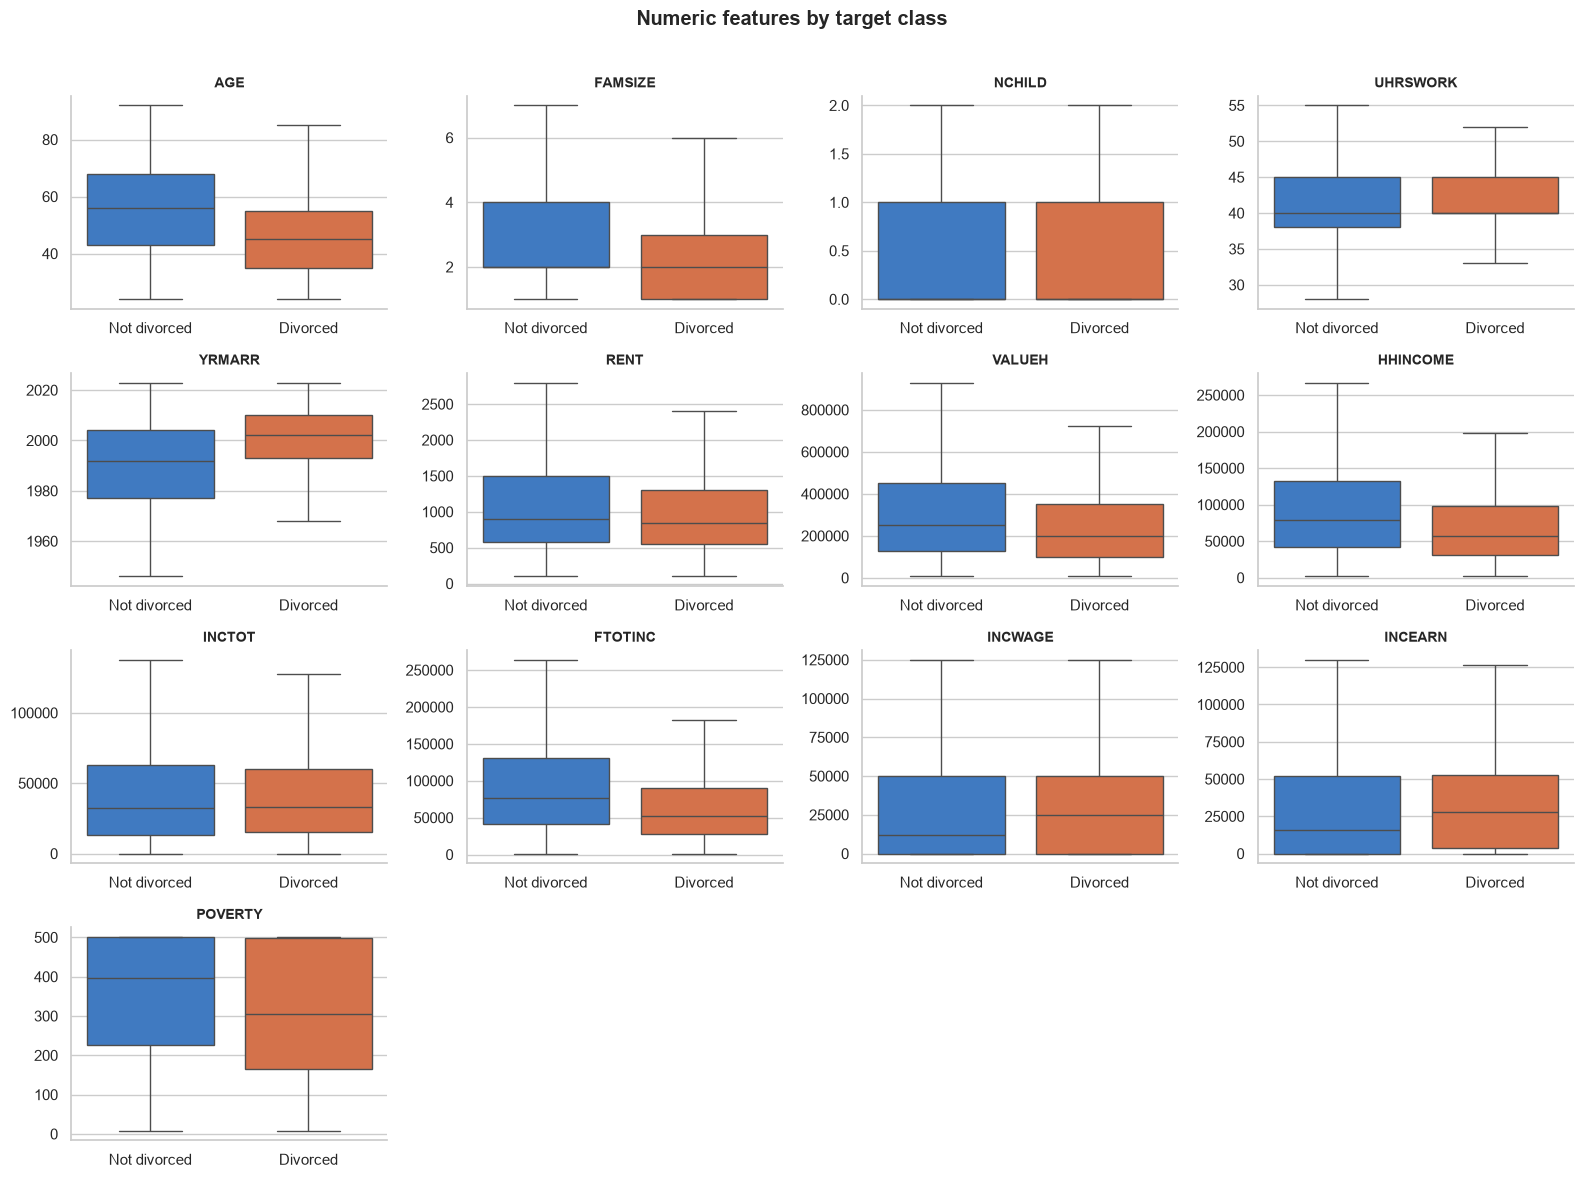

In [68]:
# Numeric features vs target: distributions by class (1st–99th pct)
ncols = 4
nrows = int(np.ceil(len(numeric_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
tmp = num.assign(**{TARGET: df[TARGET]})
for ax, c in zip(axes.flat, numeric_cols):
    lo, hi = tmp[c].quantile([.01, .99])
    sns.boxplot(data=tmp.assign(**{c: tmp[c].clip(lo, hi)}), x=TARGET, y=c,
                hue=TARGET, palette=CLASS_PALETTE, legend=False,
                showfliers=False, ax=ax)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks([0, 1], ["Not divorced", "Divorced"])
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
fig.suptitle("Numeric features by target class", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "06_numeric_vs_target")

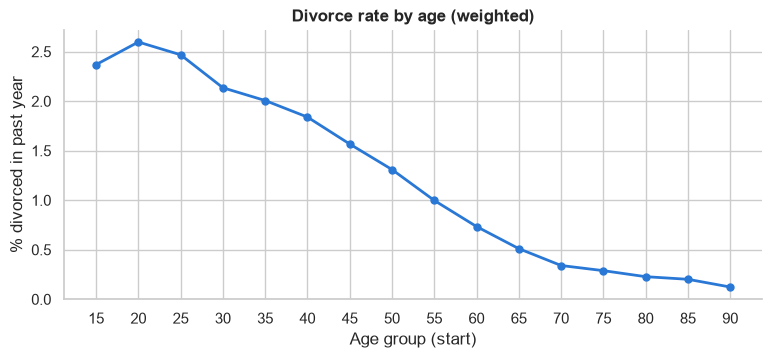

In [69]:
# Divorce rate across age – non-linear relationships show up here
age_bins = pd.cut(num["AGE"], bins=range(15, 100, 5), right=False)
age_rate = df.groupby(age_bins, observed=True).apply(
    lambda g: 100 * weighted_rate(g[TARGET], g[WEIGHT]))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot([str(i.left) for i in age_rate.index], age_rate.values,
        color=BLUE, lw=2, marker="o", ms=5)
ax.set_xlabel("Age group (start)")
ax.set_ylabel("% divorced in past year")
ax.set_title("Divorce rate by age (weighted)")
save(fig, "06_rate_by_age")

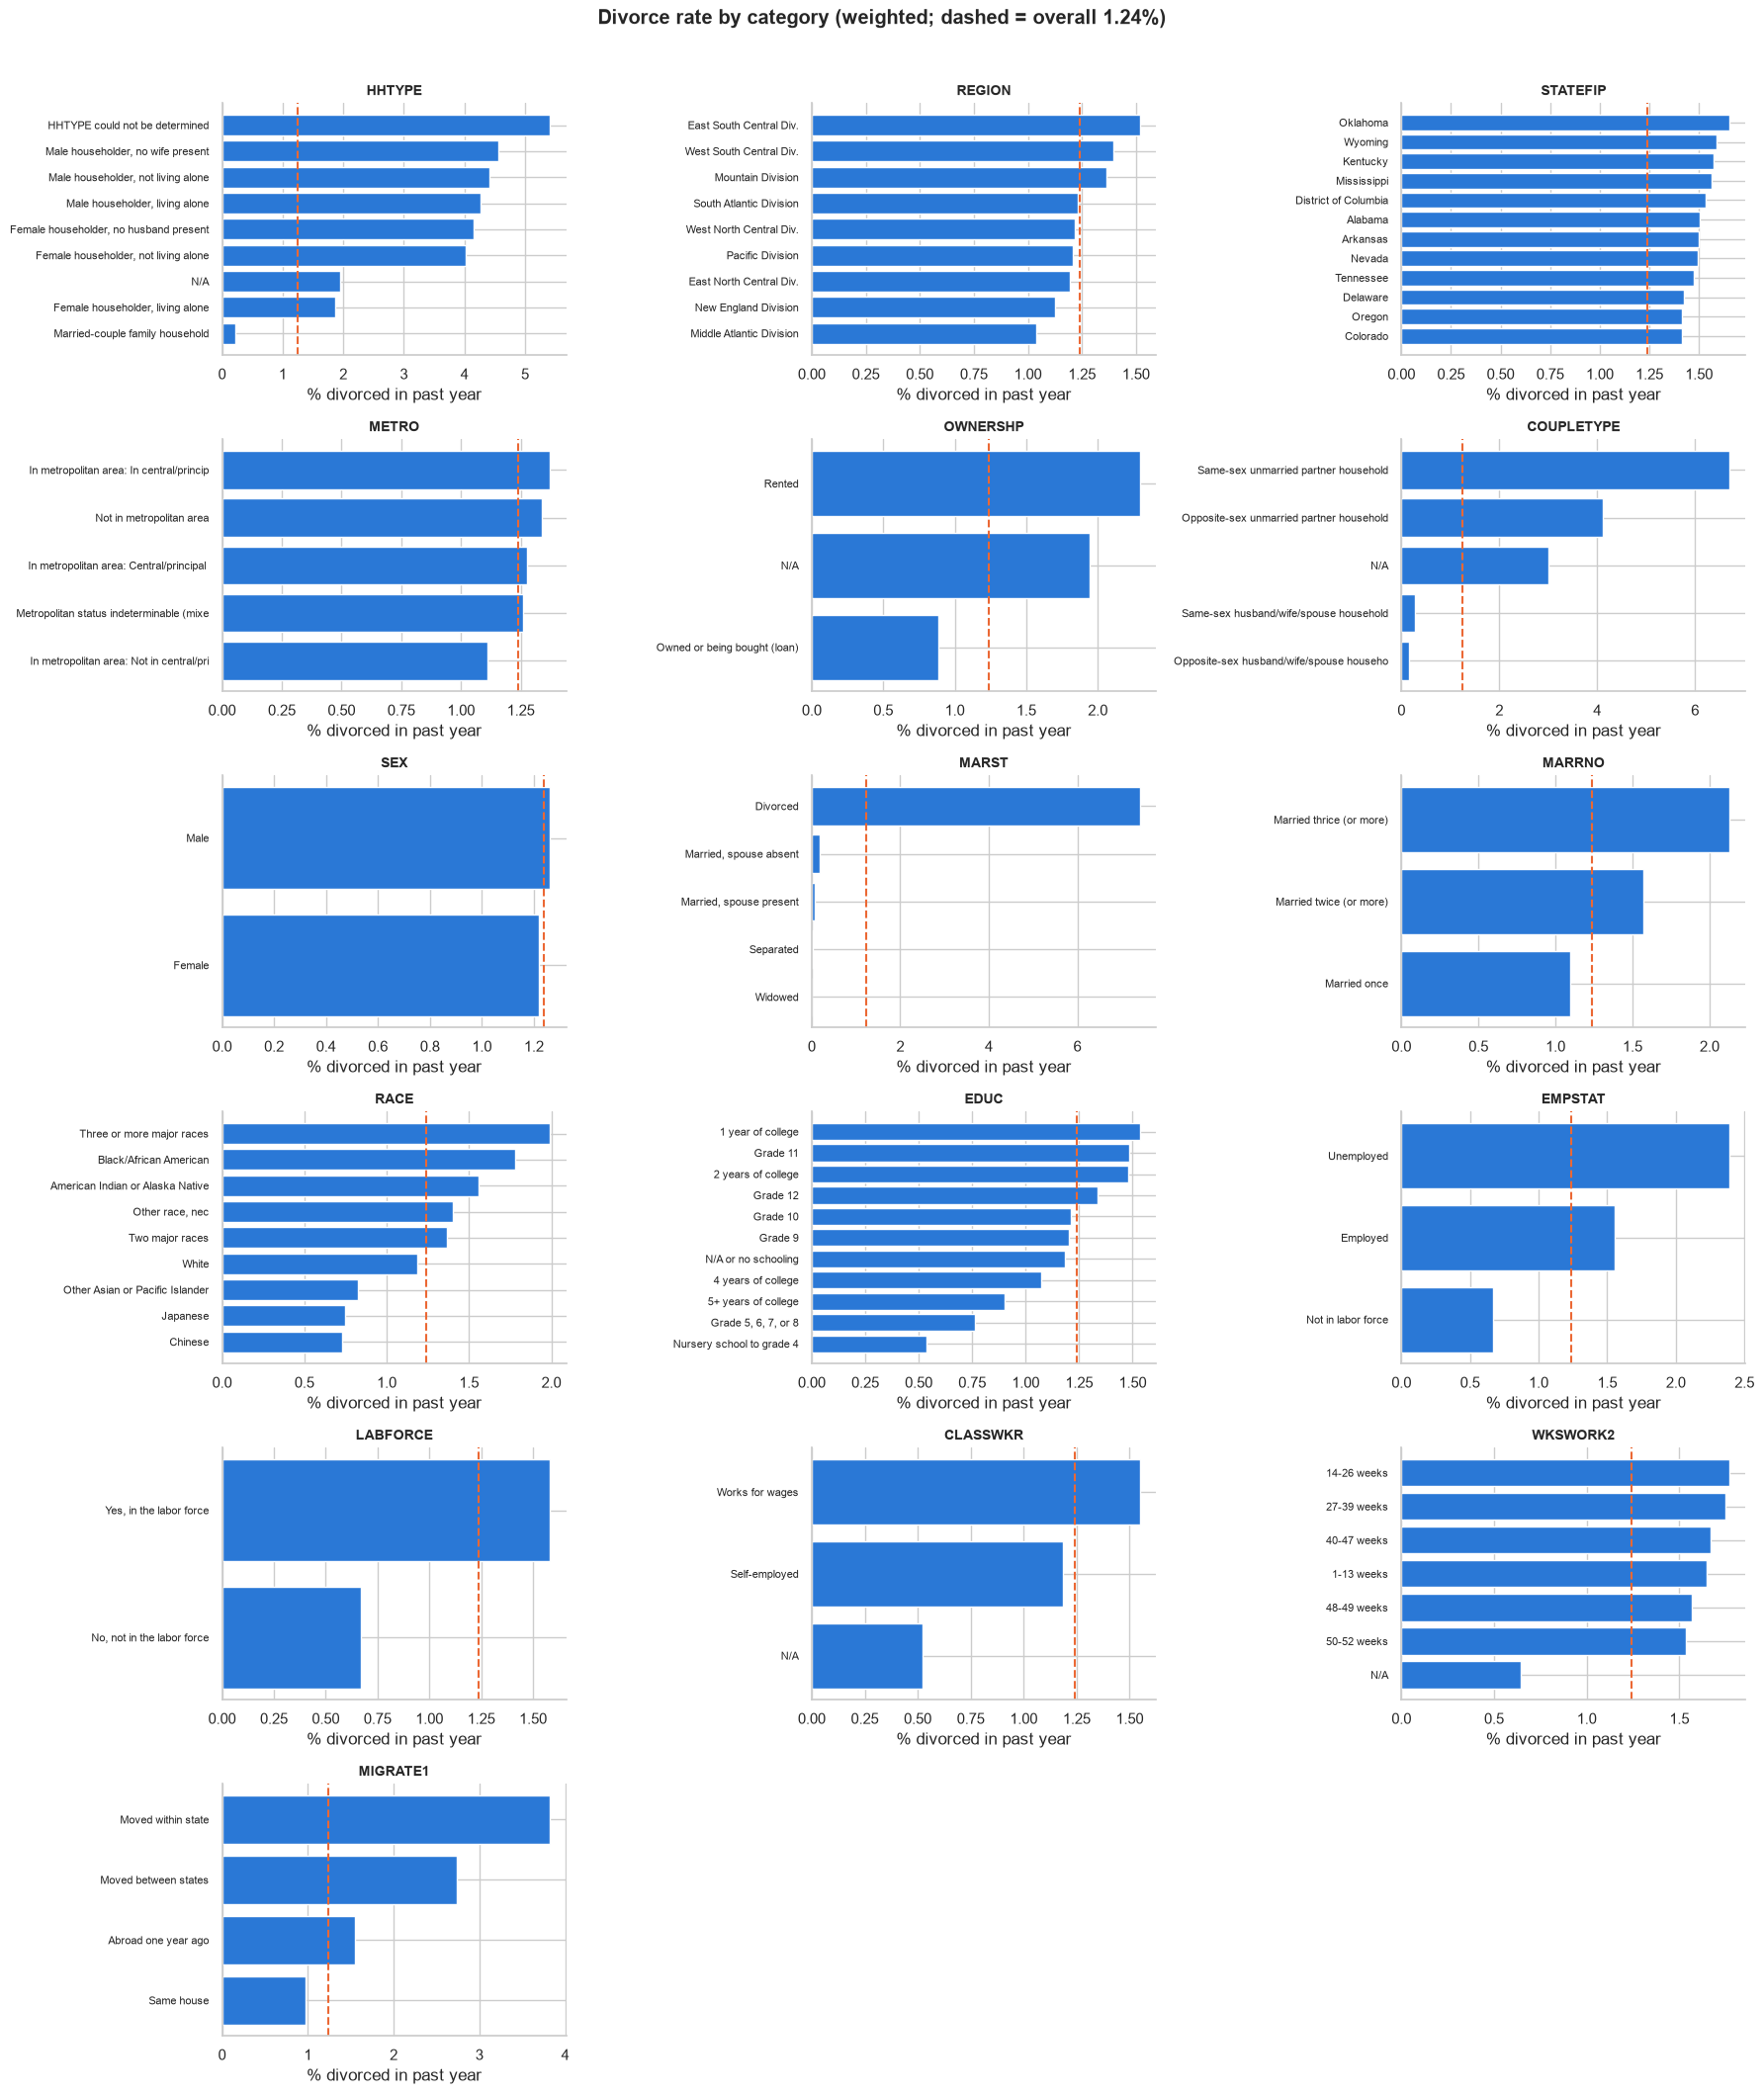

In [70]:
# Categorical features vs target: weighted divorce rate per level
overall = 100 * weighted_rate(df[TARGET], df[WEIGHT])
ncols = 3
nrows = int(np.ceil(len(feature_label_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, c in zip(axes.flat, feature_label_cols):
    g = df.groupby(c, observed=True)
    rates = g.apply(lambda x: 100 * weighted_rate(x[TARGET], x[WEIGHT]))
    rates = rates[g.size() >= 100]             # hide unstable tiny levels
    rates = rates.sort_values().tail(12)
    ax.barh([str(i)[:40] for i in rates.index], rates.values, color=BLUE)
    ax.axvline(overall, color=ORANGE, ls="--", lw=1.5)
    ax.set_title(c.replace("_LABEL", ""), fontsize=10)
    ax.set_xlabel("% divorced in past year")
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(feature_label_cols):]:
    ax.remove()
fig.suptitle(f"Divorce rate by category (weighted; dashed = overall {overall:.2f}%)",
             fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "06_categorical_vs_target")

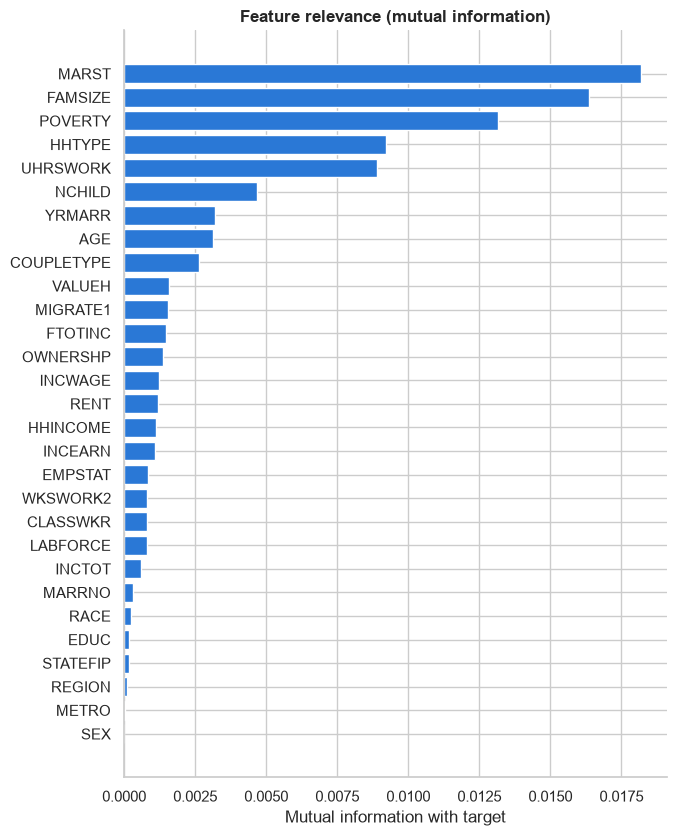

In [71]:
# Mutual information ranking (model-free, captures non-linear signal).
# Computed on a sample for speed.
mi_df = df.sample(n=min(len(df), 300_000), random_state=RANDOM_STATE)
X_mi = pd.concat([
    num.loc[mi_df.index].fillna(-1),
    mi_df[feature_label_cols].apply(lambda s: s.cat.codes),
], axis=1)
discrete = [False] * len(numeric_cols) + [True] * len(feature_label_cols)
mi = pd.Series(mutual_info_classif(X_mi, mi_df[TARGET], discrete_features=discrete,
                                   random_state=RANDOM_STATE),
               index=X_mi.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 0.3 * len(mi) + 1))
ax.barh(mi.index.str.replace("_LABEL", ""), mi.values, color=BLUE)
ax.set_xlabel("Mutual information with target")
ax.set_title("Feature relevance (mutual information)")
save(fig, "06_mutual_information")

In [72]:
# Leakage check: features that (partly) encode the outcome itself.
# Someone divorced in the past year is, by definition, currently divorced or
# recently remarried, so MARST / MARRNO / YRMARR describe the *result*.
leak_candidates = ["MARST_LABEL", "MARRNO_LABEL", "YRMARR"]
print(pd.crosstab(df["MARST_LABEL"], df[TARGET], normalize="columns").round(3))
add_issue("6 Target", ", ".join(leak_candidates),
          "Potential target leakage (marital status after the divorce event)",
          "Exclude from predictors, or justify explicitly in the report")

divorced                     0      1
MARST_LABEL                          
Divorced                 0.139  0.950
Married, spouse absent   0.031  0.005
Married, spouse present  0.711  0.043
Separated                0.023  0.001
Widowed                  0.096  0.001


## 7. Class balance

In [73]:
balance = pd.DataFrame({
    "rows": df[TARGET].value_counts(),
    "share_unweighted_%": df[TARGET].value_counts(normalize=True) * 100,
    "share_weighted_%": df.groupby(TARGET)[WEIGHT].sum() / df[WEIGHT].sum() * 100,
}).rename(index={0: "Not divorced", 1: "Divorced"}).round(3)
balance

,rows,share_unweighted_%,share_weighted_%
divorced,,,
Not divorced,5582088,98.941,98.761
Divorced,59747,1.059,1.239


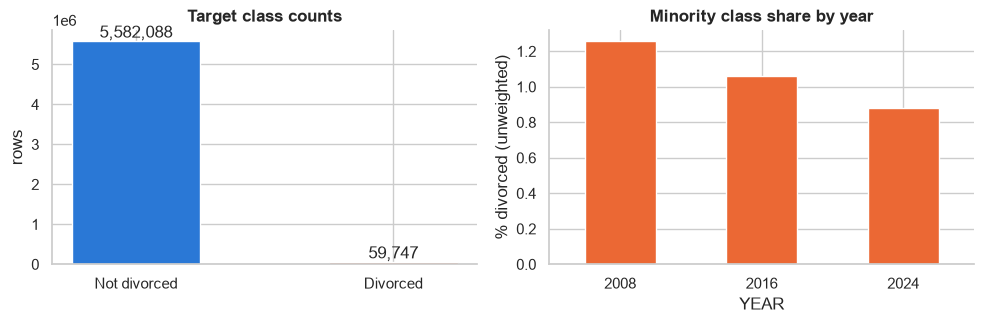

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(balance.index, balance["rows"], color=[BLUE, ORANGE], width=.5)
for x, v in enumerate(balance["rows"]):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Target class counts")
axes[0].set_ylabel("rows")

yr = df.groupby(["YEAR", TARGET]).size().unstack(fill_value=0)
(yr.div(yr.sum(axis=1), axis=0)[1] * 100).plot.bar(ax=axes[1], color=ORANGE, rot=0)
axes[1].set_title("Minority class share by year")
axes[1].set_ylabel("% divorced (unweighted)")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "07_class_balance")

In [75]:
minority = balance["share_unweighted_%"].min()
imbalance_ratio = balance["rows"].max() / balance["rows"].min()
print(f"Minority class: {minority:.2f}%  |  imbalance ratio ≈ {imbalance_ratio:,.0f}:1")
if minority < 10:
    add_issue("7 Class balance", TARGET,
              f"Severe imbalance – minority {minority:.2f}% (≈{imbalance_ratio:,.0f}:1)",
              "Stratified splits; class_weight / resampling (SMOTE, undersampling); "
              "evaluate with PR-AUC, recall, F1 – not accuracy")

Minority class: 1.06%  |  imbalance ratio ≈ 93:1


## 8. Identified problems → actions for 3.2

In [76]:
issues_df = pd.DataFrame(issues)
issues_df.to_csv(FIG_DIR / "eda_issues.csv", index=False)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(issues_df)
print(f"\n{len(issues_df)} issues saved to {FIG_DIR / 'eda_issues.csv'}; "
      f"figures in {FIG_DIR}/")

,section,feature,problem,action_3_2
0,1 Overview,(all),746 duplicate rows (0.01%); IDs removed so these may be distinct people,Keep (survey weights apply per person); verify with SERIAL/PERNUM if needed
1,1 Overview,DIVINYR_LABEL,0.0% of rows have no target (N/A or Suppressed),"Restrict modelling data to DIVINYR in {Yes, Blank (No)}"
2,2 Missing,RENT,82.5% missing / N/A,"Mostly structural N/A: drop, or encode as 0 + 'is_NA' flag"
3,2 Missing,COUPLETYPE_LABEL,73.4% missing / N/A,"Mostly structural N/A: drop, or encode as 0 + 'is_NA' flag"
4,2 Missing,WKSWORK2_LABEL,38.5% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
5,2 Missing,UHRSWORK,38.5% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
6,2 Missing,CLASSWKR_LABEL,29.3% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
7,2 Missing,VALUEH,21.4% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
8,2 Missing,HHTYPE_LABEL,5.6% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
9,2 Missing,POVERTY,2.5% missing / N/A,Simple imputation or drop rows



57 issues saved to /Users/artyomborodovitsyn/Desktop/SFU/temp454/divorce-analysis/report_outputs/figures/eda/eda_issues.csv; figures in /Users/artyomborodovitsyn/Desktop/SFU/temp454/divorce-analysis/report_outputs/figures/eda/


## Part C — 3.2 Data preprocessing: before → what we used → after

Each step is shown as **before** (the state of the data), **what we used** (decision table: technique, rule, measured evidence) and **after** (panel (b) of the figures). The rows are split once per year (stratified, 80 % training / 20 % test); cap bounds, medians, scaling, feature scores and PCA are fitted on the **training rows only**. The top-k variables by mutual information form a **reduced** feature set kept next to the **full** one.

| Subsection | Figures |
|---|---|
| 3.2.1 Missing values and outliers | ba01, ba02 |
| 3.2.2 Normalization and encoding | ba03, ba05 |
| 3.2.3 Feature selection | ba04, ba06, ba07, ba08 |
| 3.2.4 PCA | ba09, ba10, ba11 |

In [77]:
REPORT_DIR = OUT_DIR / "final_reports"                       # result tables written by the cleaning step
BEFORE_DIR = AFTER_DIR = REPORT_DIR
FIG32_DIR = OUT_DIR / "figures"
for d in (REPORT_DIR, FIG32_DIR):
    d.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

In [78]:
DIVINYR_COL, YEAR_COL, WEIGHT_COL = "DIVINYR", "YEAR", "PERWT"
NUMERIC_VARS = ["AGE", "FAMSIZE", "NCHILD", "UHRSWORK", "YRMARR", "RENT", "VALUEH",
                "HHINCOME", "INCTOT", "FTOTINC", "INCWAGE", "INCEARN", "POVERTY"]
CATEGORICAL_VARS = ["HHTYPE", "REGION", "STATEFIP", "METRO", "OWNERSHP", "COUPLETYPE", "SEX", "MARST",
                    "MARRNO", "RACE", "EDUC", "EMPSTAT", "LABFORCE", "CLASSWKR", "WKSWORK2", "MIGRATE1"]
MONEY_VARS = ["INCTOT", "FTOTINC", "INCEARN", "HHINCOME", "INCWAGE", "VALUEH", "RENT"]   # capped
SENTINELS = {"AGE": [999], "UHRSWORK": [0], "YRMARR": [0], "RENT": [0], "VALUEH": [9999998, 9999999],
             "HHINCOME": [9999999], "INCTOT": [9999998, 9999999], "FTOTINC": [9999998, 9999999],
             "INCWAGE": [999998, 999999], "INCEARN": [9999998, 9999999], "POVERTY": [0]}
STRUCTURAL_ZERO = ["UHRSWORK", "RENT", "VALUEH"]
MISSING_LABEL_RE = re.compile(r"missing|unknown|illegible|not identified|could not be determined|"
                              r"unclassifiable|suppressed", re.IGNORECASE)
MISSING_CATEGORY = "Missing"

Z_THRESHOLD = 3.0
MISSING_FLAG_SHARE = 0.01        # numeric variable gets an indicator when >= 1% missing
UNAVAILABLE_SHARE = 0.50         # categorical variable blank in >= 50% of a whole year -> removed
REDUNDANT_THRESHOLD = 0.90
# variable removed -> the partner that stays (only removed when the measured association >= threshold)
DROP_DUPLICATES = {"LABFORCE": "EMPSTAT", "STATEFIP": "REGION", "HHINCOME": "FTOTINC", "INCWAGE": "INCEARN"}
SITUATIONAL = ["MARST", "HHTYPE", "MIGRATE1"]
N_BINS, TOP_K, VARIANCE_TARGET = 20, 15, 0.40
TEST_SIZE = 0.20                 # share of the rows held out; every statistic below is fitted on the other rows
CHUNK, EVIDENCE_ROWS, SAMPLE_ROWS, SEED = 200_000, 1_000_000, 280_000, 0


def pct(a, b):
    return 100.0 * a / b if b else np.nan


def short_name(col):
    return col[:-6] if col.endswith("_LABEL") else col


def clean_name(text):
    return re.sub(r"[^0-9A-Za-z]+", "_", str(text)).strip("_")


# ----------------------------------------------------------------------------- loading
def select_columns(header):
    wanted = {YEAR_COL, WEIGHT_COL} | set(NUMERIC_VARS)
    for v in CATEGORICAL_VARS + [DIVINYR_COL]:
        if v + "_LABEL" in header:
            wanted.add(v + "_LABEL")
        elif v in header:
            wanted.add(v)
        else:
            print(f"WARNING: variable {v} not found in the file.")
    return [c for c in header if c in wanted]


def build_target(frame):
    if DIVINYR_COL + "_LABEL" in frame.columns:
        lab = frame[DIVINYR_COL + "_LABEL"].astype(str).str.strip().str.lower()
        yes = lab.eq("yes").to_numpy()
        no = (lab.str.startswith("blank (no)") | lab.eq("no")).to_numpy()
        ok = yes | no
        print(f"Eligible rows: {ok.sum():,} (dropping {(~ok).sum():,} N/A or suppressed)")
        out = frame.loc[ok].drop(columns=[DIVINYR_COL + "_LABEL"]).reset_index(drop=True)
        out[DIVINYR_COL] = yes[ok].astype("int8")
        return out
    raise SystemExit("DIVINYR_LABEL not found.")


# ----------------------------------------------------------------------------- missing values
def sentinels_to_nan(df, num_cols):
    rows = []
    for col in num_cols:
        for code in SENTINELS.get(col, []):
            m = (df[col] == code).to_numpy()
            rows.append({"variable": col, "code": code, "n_rows": int(m.sum()), "pct_rows": pct(m.sum(), len(df))})
            df.loc[m, col] = np.nan
    return pd.DataFrame(rows)


def missing_table(df, num_cols, cat_cols, years, year_arr):
    """Per variable and year: share 'not applicable' (kept as 0 / an explicit level) and share
    'missing' (imputed)."""
    rows = []
    for col in num_cols:
        na = df[col].isna().to_numpy()
        for yr in years:
            m = year_arr == yr
            share = pct(na[m].sum(), m.sum())
            rows.append({"variable": col, "year": yr, "pct_not_applicable": share if col in STRUCTURAL_ZERO else 0.0,
                         "pct_missing": 0.0 if col in STRUCTURAL_ZERO else share})
    for col in cat_cols:
        cats = list(df[col].cat.categories)
        codes = df[col].cat.codes.to_numpy()
        bad = [i for i, c in enumerate(cats) if MISSING_LABEL_RE.search(str(c)) or str(c).strip() == ""]
        miss = (codes == -1) | np.isin(codes, bad)
        nap = codes == (cats.index("N/A") if "N/A" in cats else -2)
        for yr in years:
            m = year_arr == yr
            rows.append({"variable": short_name(col), "year": yr, "pct_not_applicable": pct(nap[m].sum(), m.sum()),
                         "pct_missing": pct(miss[m].sum(), m.sum())})
    return pd.DataFrame(rows)


def fill_categories(df, cat_cols):
    for col in cat_cols:
        s = df[col]
        bad = [c for c in s.cat.categories if MISSING_LABEL_RE.search(str(c)) or str(c).strip() == ""]
        if bad:
            s = s.cat.remove_categories(bad)
        if s.isna().any():
            if MISSING_CATEGORY not in s.cat.categories:
                s = s.cat.add_categories([MISSING_CATEGORY])
            s = s.fillna(MISSING_CATEGORY)
        df[col] = s


# ----------------------------------------------------------------------------- outliers
def stratified_train_mask(year_arr, y_arr, test_size, seed):
    """Per year, stratified on the target: True = training row, False = test row."""
    rng = np.random.default_rng(seed)
    train = np.ones(len(y_arr), dtype=bool)
    for yr in np.unique(year_arr):
        for cls in (0, 1):
            idx = np.flatnonzero((year_arr == yr) & (y_arr == cls))
            rng.shuffle(idx)
            train[idx[: int(round(len(idx) * test_size))]] = False
    return train


def cap_money(df, vars_, years, year_arr, y_arr, train):
    rows = []
    for col in vars_:
        x = df[col].to_numpy(dtype="float64", copy=True)
        for yr in years:
            idx = np.flatnonzero(year_arr == yr)
            v = x[idx]
            ok = ~np.isnan(v)
            fit = ok & train[idx]                                    # bounds from the training rows only
            mu, sd = v[fit].mean(), v[fit].std()
            if sd == 0:
                continue
            with np.errstate(invalid="ignore"):
                flag = np.abs((v - mu) / sd) > Z_THRESHOLD
            lo, hi = mu - Z_THRESHOLD * sd, mu + Z_THRESHOLD * sd
            d, n = y_arr[idx] == 1, y_arr[idx] == 0
            rows.append({"variable": col, "year": yr, "mean": mu, "std": sd, "lower_bound": lo, "upper_bound": hi,
                         "n_flagged": int(flag.sum()), "pct_flagged": pct(flag.sum(), len(flag)),
                         "pct_flagged_divorced": pct(flag[d].sum(), d.sum()),
                         "pct_flagged_not_divorced": pct(flag[n].sum(), n.sum())})
            x[idx] = np.clip(v, lo, hi)
        df[col] = x.astype("float32")
    return pd.DataFrame(rows)


def impute_numeric(df, num_cols, train):
    """Median of the year, taken from the training rows only."""
    for c in num_cols:
        if c in STRUCTURAL_ZERO:
            df[c] = df[c].fillna(0)
        elif df[c].isna().any():
            med_year = df.loc[train].groupby(YEAR_COL, observed=True)[c].median()
            df[c] = df[c].fillna(df[YEAR_COL].map(med_year).astype("float64")).fillna(df.loc[train, c].median())


# ----------------------------------------------------------------------------- association
def cramers_v(a, na, b, nb):
    t = np.bincount(a * nb + b, minlength=na * nb).reshape(na, nb).astype("float64")
    n = t.sum()
    r, c = t.sum(1, keepdims=True), t.sum(0, keepdims=True)
    e = r @ c / n
    ok = e > 0
    chi2 = (((t - e) ** 2) / np.where(ok, e, 1))[ok].sum()
    k = min((r > 0).sum() - 1, (c > 0).sum() - 1)
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else 0.0


# ----------------------------------------------------------------------------- mutual information
def mi_from_table(table):
    t = np.asarray(table, dtype="float64")
    n = t.sum()
    if n == 0:
        return 0.0
    p = t / n
    e = p.sum(axis=1, keepdims=True) @ p.sum(axis=0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log(p[nz] / e[nz])).sum())


def target_entropy(n_pos, n):
    p = n_pos / n
    return float(-(p * np.log(p) + (1 - p) * np.log(1 - p))) if 0 < p < 1 else 0.0


def mi_tables(num_mat, num_names, cat_codes, cat_levels, ind_masks, year_arr, y_arr, years, train):
    rows = []
    for yr in years:
        idx = np.flatnonzero((year_arr == yr) & train)          # training rows only
        y = y_arr[idx].astype("int64")
        n, n_pos = len(y), int(y.sum())
        h = target_entropy(n_pos, n)
        to_pct = lambda mi: 100.0 * mi / h if h > 0 else np.nan
        for j, col in enumerate(num_names):
            x = num_mat[idx, j]
            edges = np.unique(np.quantile(x, np.linspace(0, 1, N_BINS + 1)[1:-1]))
            t = np.bincount(np.searchsorted(edges, x, side="right") * 2 + y, minlength=2 * (len(edges) + 1)).reshape(-1, 2)
            mi = mi_from_table(t)
            rows.append({"year": yr, "variable": col, "type": "numeric", "mi_nats": mi, "mi_pct_of_target_entropy": to_pct(mi)})
        for name, m in ind_masks.items():
            t = np.bincount(m[idx].astype("int64") * 2 + y, minlength=4).reshape(-1, 2)
            mi = mi_from_table(t)
            rows.append({"year": yr, "variable": name, "type": "indicator", "mi_nats": mi, "mi_pct_of_target_entropy": to_pct(mi)})
        for v, codes in cat_codes.items():
            L = len(cat_levels[v])
            t = np.bincount(codes[idx].astype("int64") * 2 + y, minlength=2 * L).reshape(L, 2)
            mi = mi_from_table(t)
            rows.append({"year": yr, "variable": v, "type": "categorical", "mi_nats": mi, "mi_pct_of_target_entropy": to_pct(mi)})
    return pd.DataFrame(rows)


def pca_tables(design_block, feature_names, years, year_arr, y_arr, rng, train):
    """Exact PCA per year, FITTED on the training rows (chunked covariance). Class separation and the
    PC1/PC2 sample are computed on the TEST rows, projected with the training components."""
    summary, ev_rows, top_rows, sep_frames, scatter_rows = [], [], [], [], []
    for yr in years:
        idx = np.flatnonzero((year_arr == yr) & train)           # fit
        idx_te = np.flatnonzero((year_arr == yr) & ~train)       # evaluate
        p = len(feature_names)
        n, s, xtx = 0, np.zeros(p), np.zeros((p, p))
        for i in range(0, len(idx), CHUNK):
            x = design_block(idx[i:i + CHUNK], yr).astype("float64")
            n += len(x); s += x.sum(axis=0); xtx += x.T @ x
        mean = s / n
        w, v = np.linalg.eigh((xtx - n * np.outer(mean, mean)) / (n - 1))
        order = np.argsort(w)[::-1]
        w, v = np.clip(w[order], 0, None), v[:, order]
        sg = np.sign(v[np.abs(v).argmax(axis=0), np.arange(p)]); sg[sg == 0] = 1
        v = v * sg
        ratio = w / w.sum(); cum = np.cumsum(ratio)
        ks = {t: int(np.searchsorted(cum, t) + 1) for t in (VARIANCE_TARGET, 0.8, 0.9)}
        k = ks[VARIANCE_TARGET]
        summary.append({"year": yr, "n_rows": n, "n_features": p, "n_components": k, "variance_retained": cum[k - 1],
                        "components_for_80pct": ks[0.8], "components_for_90pct": ks[0.9]})
        ev_rows += [{"year": yr, "component": f"PC{i + 1}", "eigenvalue": w[i], "explained_ratio": ratio[i],
                     "cumulative_ratio": cum[i]} for i in range(p)]
        for j in range(min(5, p)):
            for rank, i in enumerate(np.argsort(-np.abs(v[:, j]))[:8], start=1):
                top_rows.append({"year": yr, "component": f"PC{j + 1}", "explained_ratio": ratio[j], "rank": rank,
                                 "feature": feature_names[i], "loading": v[i, j]})
        acc = {c: [np.zeros(k), np.zeros(k), 0] for c in (0, 1)}
        for i in range(0, len(idx_te), CHUNK):
            sub = idx_te[i:i + CHUNK]
            sc = (design_block(sub, yr).astype("float64") - mean) @ v[:, :k]
            yy = y_arr[sub]
            for c in (0, 1):
                mm = yy == c
                if mm.any():
                    acc[c][0] += sc[mm].sum(axis=0); acc[c][1] += (sc[mm] ** 2).sum(axis=0); acc[c][2] += int(mm.sum())
        st = {c: (acc[c][0] / acc[c][2], (acc[c][1] - acc[c][2] * (acc[c][0] / acc[c][2]) ** 2) / (acc[c][2] - 1), acc[c][2]) for c in (0, 1)}
        pooled = np.sqrt(((st[1][2] - 1) * st[1][1] + (st[0][2] - 1) * st[0][1]) / (st[1][2] + st[0][2] - 2))
        d = np.where(pooled > 0, (st[1][0] - st[0][0]) / np.where(pooled > 0, pooled, 1), 0)
        sep_frames.append(pd.DataFrame({"year": yr, "component": [f"PC{i + 1}" for i in range(k)],
                                        "mean_divorced": st[1][0], "mean_not_divorced": st[0][0], "cohens_d": d}))
        yy = y_arr[idx_te]
        pick = np.concatenate([rng.choice(idx_te[yy == 0], size=min(20000, int((yy == 0).sum())), replace=False),
                               rng.choice(idx_te[yy == 1], size=min(3000, int((yy == 1).sum())), replace=False)])
        sc2 = (design_block(pick, yr).astype("float64") - mean) @ v[:, :2]
        scatter_rows.append(pd.DataFrame({"year": yr, "DIVINYR": y_arr[pick], "PC1": sc2[:, 0], "PC2": sc2[:, 1]}))
        print(f"  PCA {yr}: {k} components reach {cum[k - 1]:.3f} (80%: {ks[0.8]}, 90%: {ks[0.9]}) on {p} columns, fitted on {n:,} training rows")
    return {"summary": pd.DataFrame(summary), "ev": pd.DataFrame(ev_rows), "top": pd.DataFrame(top_rows),
            "sep": pd.concat(sep_frames), "scatter": pd.concat(scatter_rows)}

In [79]:
def run_cleaning(df_in, exclude_situational=False):
    """Apply every cleaning rule to the decoded data; the evidence and result tables are written to REPORT_DIR."""
    t0 = time.time()
    df = build_target(df_in)
    num_cols = [c for c in NUMERIC_VARS if c in df.columns]
    cat_cols = [c for c in df.columns if c not in num_cols + [YEAR_COL, WEIGHT_COL, DIVINYR_COL]]
    year_arr, y_arr = df[YEAR_COL].to_numpy(), df[DIVINYR_COL].to_numpy()
    years = sorted(np.unique(year_arr).tolist())
    N = len(df)
    print(f"{N:,} rows, {int(y_arr.sum()):,} divorced ({pct(y_arr.sum(), N):.3f}%), years {years}")

    decisions = []
    def log(stage, technique, variables, rule, evidence, result=""):
        decisions.append({"section": stage, "technique": technique, "variables": variables,
                          "rule_or_threshold": rule, "evidence_measured": evidence, "result": result})

    class_balance = (df.groupby(YEAR_COL, observed=True)[DIVINYR_COL].agg(n_rows="size", n_divorced="sum", pct_divorced="mean")
                     .reset_index())
    class_balance["pct_divorced"] *= 100
    class_balance[YEAR_COL] = class_balance[YEAR_COL].astype(str)      # so the "All" row can be added without a dtype warning
    class_balance.loc[len(class_balance)] = ["All", N, int(y_arr.sum()), pct(y_arr.sum(), N)]
    class_balance.to_csv(REPORT_DIR / "final_class_balance.csv", index=False)

    # ---------------- train / test split (stratified per year); every statistic below is fitted on the training rows
    train = stratified_train_mask(year_arr, y_arr, TEST_SIZE, SEED)
    split = pd.DataFrame([{"year": yr, "set": name, "n_rows": int(((year_arr == yr) & m).sum()),
                           "n_divorced": int(((year_arr == yr) & m & (y_arr == 1)).sum())}
                          for yr in years for name, m in (("train", train), ("test", ~train))])
    split["pct_divorced"] = 100.0 * split.n_divorced / split.n_rows
    split.to_csv(REPORT_DIR / "final_split_summary.csv", index=False)
    print(f"Train/test split: {int(train.sum()):,} training rows, {int((~train).sum()):,} test rows")

    # ---------------- 3.2.1 missing values (BEFORE state recorded first)
    audit = sentinels_to_nan(df, num_cols)
    miss = missing_table(df, num_cols, cat_cols, years, year_arr)
    miss.to_csv(REPORT_DIR / "final_missing_before.csv", index=False)

    rng = np.random.default_rng(SEED)
    sample_idx = np.sort(rng.choice(N, size=min(SAMPLE_ROWS, N), replace=False))
    before_vals = df.loc[sample_idx, num_cols].to_numpy(dtype="float32").copy()

    # ---------------- decisions: unavailable variables (measured on the raw labels)
    dropped = {}
    unavailable_evidence = {}
    for col in cat_cols:
        blank = miss[(miss.variable == short_name(col))].set_index("year").pct_missing
        if blank.max() >= 100 * UNAVAILABLE_SHARE:
            dropped[short_name(col)] = "unavailable in some years"
            unavailable_evidence[short_name(col)] = ", ".join(f"{yr}: {blank[yr]:.0f}%" for yr in years)

    # ---------------- process ALL variables (needed to measure the redundancy)
    money = [v for v in MONEY_VARS if v in num_cols]
    cap_stats = cap_money(df, money, years, year_arr, y_arr, train)
    masks = {}
    for c in num_cols:
        if c not in STRUCTURAL_ZERO:
            m = df[c].isna().to_numpy()
            if m.mean() >= MISSING_FLAG_SHARE:
                masks[c] = m
    n_missing_rows = {c: int(m.sum()) for c, m in masks.items()}
    impute_numeric(df, num_cols, train)
    fill_categories(df, cat_cols)
    cat_short = {c: short_name(c) for c in cat_cols}
    cat_codes = {cat_short[c]: df[c].cat.codes.to_numpy().astype(np.int64) for c in cat_cols}
    cat_levels = {cat_short[c]: list(df[c].cat.categories) for c in cat_cols}
    num_all = df[num_cols].to_numpy(dtype="float32")

    # ---------------- evidence for near-duplicates
    tr_rows = np.flatnonzero(train)
    ev_idx = np.sort(rng.choice(tr_rows, size=min(EVIDENCE_ROWS, len(tr_rows)), replace=False))
    spearman = pd.DataFrame(num_all[ev_idx].astype("float64"), columns=num_cols).corr(method="spearman")
    vnames = list(cat_codes)
    cramer = pd.DataFrame(np.eye(len(vnames)), index=vnames, columns=vnames)
    for i in range(len(vnames)):
        for j in range(i + 1, len(vnames)):
            a, b = vnames[i], vnames[j]
            cramer.iat[i, j] = cramer.iat[j, i] = cramers_v(cat_codes[a][tr_rows], len(cat_levels[a]), cat_codes[b][tr_rows], len(cat_levels[b]))
    spearman.to_csv(REPORT_DIR / "final_corr_numeric.csv")
    cramer.to_csv(REPORT_DIR / "final_cramers_v.csv")

    pair_evidence = {}
    for drop, keep in DROP_DUPLICATES.items():
        if drop in dropped:
            continue
        if drop in num_cols and keep in num_cols:
            val, kind = abs(float(spearman.loc[drop, keep])), "Spearman"
        elif drop in cat_codes and keep in cat_codes:
            val, kind = float(cramer.loc[drop, keep]), "Cramer's V"
        else:
            print(f"WARNING: cannot evaluate {drop} vs {keep}")
            continue
        if val >= REDUNDANT_THRESHOLD:
            dropped[drop] = f"duplicate of {keep}"
            pair_evidence[drop] = f"{kind} with {keep} = {val:.2f}"
        else:
            print(f"WARNING: {drop} vs {keep}: {kind} = {val:.2f} < {REDUNDANT_THRESHOLD}; {drop} is kept.")
    if exclude_situational:
        for v in SITUATIONAL:
            dropped[v] = "situational (describes life after or around a divorce)"
    print("Removed variables:", {k: v for k, v in dropped.items()})

    num_final = [c for c in num_cols if c not in dropped]
    cat_final = [cat_short[c] for c in cat_cols if cat_short[c] not in dropped]

    # ---------------- merge indicators that flag exactly the same rows
    groups = {}
    for c, m in masks.items():
        if c in num_final:
            groups.setdefault(np.packbits(m).tobytes(), []).append(c)
    ind_groups = {"_".join(v) + "_MISSING": (v, masks[v[0]]) for v in groups.values()}
    ind_names = list(ind_groups)

    # ---------------- the final dataset
    fin = pd.DataFrame({YEAR_COL: df[YEAR_COL], WEIGHT_COL: df[WEIGHT_COL].astype("float32"), DIVINYR_COL: df[DIVINYR_COL]})
    for c in num_final:
        fin[c] = df[c].round().astype("int32")
    for name, (_, m) in ind_groups.items():
        fin[name] = m.astype("int8")
    for c in cat_cols:
        if cat_short[c] in cat_final:
            fin[cat_short[c]] = df[c]
    assert not fin.isna().any().any(), "NaN left in the final dataset"

    # ---------------- the funnel (variables and encoded columns at each stage)
    def n_cols(nums, cats, n_ind):
        return len(nums) + n_ind + sum(len(cat_levels[v]) for v in cats)
    all_cat = [cat_short[c] for c in cat_cols]
    stages = [("Candidate variables", num_cols, all_cat, len(masks), "")]
    s1_num = [c for c in num_cols if dropped.get(c, "").startswith("unavailable") is False]
    un = [v for v, r in dropped.items() if r.startswith("unavailable")]
    dup = [v for v, r in dropped.items() if r.startswith("duplicate")]
    sit = [v for v, r in dropped.items() if r.startswith("situational")]
    n1, c1 = [c for c in num_cols if c not in un], [c for c in all_cat if c not in un]
    stages.append((f"Remove unavailable ({', '.join(un) or 'none'})", n1, c1, sum(1 for c in masks if c in n1), ""))
    n2, c2 = [c for c in n1 if c not in dup], [c for c in c1 if c not in dup]
    stages.append((f"Remove near-duplicates ({', '.join(dup) or 'none'})", n2, c2, sum(1 for c in masks if c in n2), ""))
    stages.append(("Merge identical missing-indicators", n2, c2, len(ind_names), ""))
    if sit:
        n3, c3 = [c for c in n2 if c not in sit], [c for c in c2 if c not in sit]
        stages.append((f"Remove situational ({', '.join(sit)})", n3, c3, len(ind_names), ""))
    funnel = pd.DataFrame([{"stage": s, "n_variables": len(nn) + len(cc), "n_columns": n_cols(nn, cc, ni)}
                           for s, nn, cc, ni, _ in stages])
    funnel.insert(0, "order", range(1, len(funnel) + 1))
    funnel["kind"] = "step"

    # ---------------- encoded design (final features) for scaling parameters and PCA
    num_mat = fin[num_final].to_numpy(dtype="float32")
    flag_mat = fin[ind_names].to_numpy(dtype="float32") if ind_names else np.empty((len(fin), 0), "float32")
    fcodes = {v: fin[v].cat.codes.to_numpy().astype(np.int64) for v in cat_final}
    flevels = {v: list(fin[v].cat.categories) for v in cat_final}
    scaler, srows = {}, []
    for yr in years:
        m = (year_arr == yr) & train
        x = num_mat[m].astype("float64")
        mean, std = x.mean(axis=0), x.std(axis=0)
        std = np.where(std > 0, std, 1.0)
        scaler[yr] = (mean, std)
        srows += [{"year": yr, "variable": c, "mean": mean[j], "std": std[j]} for j, c in enumerate(num_final)]
    pd.DataFrame(srows).to_csv(REPORT_DIR / "final_scaler_params.csv", index=False)
    dummy_names, offset, used = [], {}, set()
    for v in cat_final:
        offset[v] = len(dummy_names)
        for lvl in flevels[v]:
            name = f"{v}__{clean_name(lvl)}"
            base, k = name, 2
            while name in used:
                name, k = f"{base}_{k}", k + 1
            used.add(name)
            dummy_names.append(name)
    feature_names = num_final + ind_names + dummy_names
    pd.DataFrame({"variable": cat_final, "n_levels": [len(flevels[v]) for v in cat_final]}).to_csv(
        REPORT_DIR / "final_onehot_summary.csv", index=False)

    def design_block(idx, yr):
        mean, std = scaler[yr]
        z = ((num_mat[idx] - mean) / std).astype("float32")
        block = np.zeros((len(idx), len(dummy_names)), dtype="float32")
        rows = np.arange(len(idx))
        for v in cat_final:
            block[rows, offset[v] + fcodes[v][idx]] = 1.0
        return np.hstack([z, flag_mat[idx], block])
    assert len(feature_names) == n_cols(num_final, cat_final, len(ind_names)), "column count mismatch"

    # ---------------- mutual information (all variables; 'kept' marks the final set)
    mi_ind = {n: m for n, (_, m) in ind_groups.items()}
    mi = mi_tables(num_all, num_cols, cat_codes, cat_levels, mi_ind, year_arr, y_arr, years, train)
    mi["status"] = np.where(mi.variable.isin(list(dropped)), "removed", "kept")
    mi["reason"] = mi.variable.map(dropped).fillna("")
    kept_mi = mi[mi.status == "kept"].copy()
    kept_mi["rank_among_kept"] = kept_mi.groupby("year").mi_nats.rank(ascending=False, method="first").astype(int)
    mi = mi.merge(kept_mi[["year", "variable", "rank_among_kept"]], on=["year", "variable"], how="left")
    # candidate subset: the top-k VARIABLES by the mean (over years) mutual information on the training rows;
    # the full cleaned set is kept next to it so the two can be compared in the modelling phase
    mean_mi = kept_mi[kept_mi.type != "indicator"].groupby("variable").mi_pct_of_target_entropy.mean().sort_values(ascending=False)
    top_vars = list(mean_mi.index[:TOP_K])
    mi["rank_overall"] = mi.variable.map({v: i + 1 for i, v in enumerate(mean_mi.index)})
    mi["selected"] = mi.variable.isin(top_vars)
    mi.to_csv(REPORT_DIR / "final_mi_variables.csv", index=False)
    red_num = [c for c in num_final if c in top_vars]
    red_cat = [v for v in cat_final if v in top_vars]
    red_ind = [n for n, (vs, _) in ind_groups.items() if any(v in red_num for v in vs)]
    n_cols_reduced = len(red_num) + len(red_ind) + sum(len(flevels[v]) for v in red_cat)
    pd.DataFrame([{"variable": v, "type": "numeric" if v in num_final else "categorical", "rank_by_mean_train_mi": i + 1,
                   "mean_mi_pct_of_target_entropy": mean_mi[v], "in_full_set": True, "in_reduced_set": v in top_vars}
                  for i, v in enumerate(mean_mi.index)]).to_csv(REPORT_DIR / "final_feature_sets.csv", index=False)
    funnel.loc[len(funnel)] = [len(funnel) + 1, f"Select top-{TOP_K} variables (training-set mutual information)",
                               len(top_vars), n_cols_reduced, "reduced"]

    # ---------------- PCA: after = the final columns, before = all candidate columns
    pca_summary = []
    if not False:
        res = pca_tables(design_block, feature_names, years, year_arr, y_arr, rng, train)
        pca_summary = res["summary"].to_dict("records")
        for fname, key in [("final_pca_summary", "summary"), ("final_pca_explained_variance", "ev"), ("final_pca_top_loadings", "top"),
                           ("final_pca_class_separation", "sep"), ("final_pca_scatter_sample", "scatter")]:
            res[key].to_csv(REPORT_DIR / f"{fname}.csv", index=False)
        ps = res["summary"]
        for t, col in [("40%", "n_components"), ("80%", "components_for_80pct"), ("90%", "components_for_90pct")]:
            funnel.loc[len(funnel)] = [len(funnel) + 1, f"PCA components for {t} of the variance (median over years)",
                                       int(ps[col].median()), int(ps[col].median()), "pca"]
        # the same analysis BEFORE cleaning: every variable, every one-hot level, one indicator per variable
        mask_names = [c + "_MISSING" for c in masks]
        mask_mat = np.column_stack([masks[c] for c in masks]).astype("float32") if masks else np.empty((N, 0), "float32")
        scaler_b = {}
        for yr in years:
            xx = num_all[(year_arr == yr) & train].astype("float64")
            sd = xx.std(axis=0)
            scaler_b[yr] = (xx.mean(axis=0), np.where(sd > 0, sd, 1.0))
        off_b, dnames_b = {}, []
        for v in all_cat:
            off_b[v] = len(dnames_b)
            dnames_b += [f"{v}__{clean_name(l)}" for l in cat_levels[v]]

        def design_before(idx, yr):
            mean, std = scaler_b[yr]
            z = ((num_all[idx] - mean) / std).astype("float32")
            block = np.zeros((len(idx), len(dnames_b)), dtype="float32")
            rows = np.arange(len(idx))
            for v in all_cat:
                block[rows, off_b[v] + cat_codes[v][idx]] = 1.0
            return np.hstack([z, mask_mat[idx], block])

        res_b = pca_tables(design_before, num_cols + mask_names + dnames_b, years, year_arr, y_arr, rng, train)
        for fname, key in [("before_pca_summary", "summary"), ("before_pca_explained_variance", "ev"), ("before_pca_class_separation", "sep")]:
            res_b[key].to_csv(REPORT_DIR / f"{fname}.csv", index=False)
    pd.DataFrame({"variable": all_cat, "n_levels": [len(cat_levels[v]) for v in all_cat]}).to_csv(
        REPORT_DIR / "before_onehot_summary.csv", index=False)
    funnel.to_csv(REPORT_DIR / "final_feature_funnel.csv", index=False)

    # ---------------- before/after sample + missing after
    after_vals = np.full((len(sample_idx), len(num_cols)), np.nan, dtype="float32")
    pos_in_fin = {c: j for j, c in enumerate(num_final)}
    for j, c in enumerate(num_cols):
        if c in pos_in_fin:
            after_vals[:, j] = num_mat[sample_idx, pos_in_fin[c]]
    sample = pd.DataFrame({YEAR_COL: year_arr[sample_idx], DIVINYR_COL: y_arr[sample_idx]})
    for j, c in enumerate(num_cols):
        sample[c + "_before"] = before_vals[:, j]
        sample[c + "_after"] = after_vals[:, j]
    sample.to_csv(REPORT_DIR / "final_sample_before_after.csv", index=False)
    cap_stats.to_csv(REPORT_DIR / "final_outliers_capped.csv", index=False)
    audit.to_csv(REPORT_DIR / "final_missing_code_audit.csv", index=False)

    # ---------------- the decision table ("what we used")
    S0 = "3.2 All steps"
    S1, S2, S3, S4 = "3.2.1 Missing values and outliers", "3.2.2 Normalization and encoding", "3.2.3 Feature selection", "3.2.4 PCA"
    a = audit.set_index(["variable", "code"]).n_rows
    log(S0, "Stratified train/test split per year", DIVINYR_COL, f"{round((1 - TEST_SIZE) * 100)}/{round(TEST_SIZE * 100)} split, stratified on the target, seed {SEED}",
        "; ".join(f"{r.year} {r.set}: {r.n_rows:,} rows, {r.pct_divorced:.2f}% divorced" for r in split.itertuples()),
        "cap bounds, medians, scaling, feature scores and PCA are fitted on the training rows only (no leakage) and applied to every row")
    log(S1, "IPUMS 'not applicable / missing' codes -> missing", ", ".join(sorted(set(audit[audit.n_rows > 0].variable))),
        "codes from the IPUMS documentation", "; ".join(f"{r.variable} {r.code}: {r.n_rows:,} rows ({r.pct_rows:.1f}%)" for r in audit[audit.n_rows > 0].itertuples()))
    sz = {c: pct(int(np.isnan(before_vals[:, num_cols.index(c)]).sum()), len(before_vals)) for c in STRUCTURAL_ZERO if c in num_cols}
    log(S1, "'Not applicable' means none -> 0", ", ".join(sz), "no rent for owners, no house value for renters, no hours when not working",
        "; ".join(f"{c} {v:.0f}% of rows" for c, v in sz.items()))
    for v, ev in unavailable_evidence.items():
        log(S1, "Remove variable that is unavailable in some years", v, f"blank in >= {UNAVAILABLE_SHARE:.0%} of the rows of a whole year", f"% blank by year: {ev}", f"{v} removed")
    if masks:
        for key, vs in groups.items():
            log(S1, "Impute with the median of the year (training rows) + one missing-indicator", ", ".join(vs),
                f"missing in >= {MISSING_FLAG_SHARE:.0%} of rows; variables missing on exactly the same rows share ONE indicator",
                f"{', '.join(vs)} are missing on the same {n_missing_rows[vs[0]]:,} rows ({pct(n_missing_rows[vs[0]], N):.2f}%)",
                f"{len(vs)} indicator(s) merged into 1")
    cmiss = [short_name(c) for c in cat_cols if (miss[(miss.variable == short_name(c))].pct_missing.mean() > 0) and short_name(c) not in dropped]
    if cmiss:
        log(S1, "Missing categorical values -> level 'Missing' ('N/A' stays a real level)", ", ".join(cmiss), "label means missing / unknown",
            "; ".join(f"{c} {miss[miss.variable == c].pct_missing.mean():.1f}%" for c in cmiss))
    capsum = cap_stats.groupby("variable").agg(p_all=("pct_flagged", "mean"), p_div=("pct_flagged_divorced", "mean"), p_non=("pct_flagged_not_divorced", "mean"))
    log(S1, f"Cap at mean +/- {Z_THRESHOLD:g} std, computed within each year on the training rows (rows are not removed)", ", ".join(v for v in money if v in num_final),
        "z-score; money variables only (incomes, house value, rent)",
        "; ".join(f"{v}: {r.p_all:.1f}% flagged (divorced {r.p_div:.1f}%, not divorced {r.p_non:.1f}%)" for v, r in capsum.iterrows() if v in num_final))
    log(S1, "Not capped", ", ".join(c for c in num_final if c not in money), "counts, ages, years and percentages: the z-score rule is not meaningful",
        "e.g. the share of NCHILD flagged by a z-score depends only on where the threshold falls")
    log(S1, "Class imbalance: no augmentation", DIVINYR_COL, "no synthetic samples",
        f"{int(y_arr.sum()):,} divorced of {N:,} ({pct(y_arr.sum(), N):.2f}%); " + ", ".join(f"{r.YEAR}: {r.pct_divorced:.2f}%" for r in class_balance.iloc[:-1].itertuples()),
        "use stratified splits and class weights when modelling")
    for drop, why in pair_evidence.items():
        log(S3, "Remove near-duplicate variable", drop, f"association >= {REDUNDANT_THRESHOLD:.2f} with the variable that stays", why, f"{drop} removed, {DROP_DUPLICATES[drop]} kept")
    if sit:
        log(S3, "Remove situational variables", ", ".join(sit), "describe life after or around a divorce", "chosen with --exclude-situational")
    rem = spearman.loc[num_final, num_final].abs().to_numpy() - np.eye(len(num_final))
    remv = cramer.loc[[v for v in cat_final], [v for v in cat_final]].to_numpy() - np.eye(len(cat_final))
    log(S3, "Check: remaining association", "all kept variables", f"threshold {REDUNDANT_THRESHOLD:.2f}",
        f"largest remaining |Spearman| = {rem.max():.2f}; largest remaining Cramer's V = {remv.max():.2f}")
    log(S3, "Mutual information with DIVINYR on the TRAINING rows (filter method, no model)", "all kept variables",
        f"equal-frequency bins; reduced set = the top {TOP_K} variables by the mean score over the years",
        "top of the ranking (% of target entropy): " + ", ".join(f"{v} {x:.1f}%" for v, x in mean_mi.head(5).items()),
        f"full set {len(num_final) + len(cat_final)} variables / {len(feature_names)} columns is kept next to the reduced set {len(top_vars)} variables / {n_cols_reduced} columns")
    log(S2, "z-score within each year", ", ".join(num_final), "(x - mean) / std with the mean and std of the training rows of that year",
        "INCTOT mean by year: " + ", ".join(f"{yr}: {scaler[yr][0][num_final.index('INCTOT')]:,.0f}" for yr in years) if "INCTOT" in num_final else "")
    log(S2, "One-hot encoding", ", ".join(cat_final), "one 0/1 column per level, identical columns in every year",
        f"{sum(len(flevels[v]) for v in cat_final)} one-hot columns; {len(feature_names)} columns in total")
    log(S4, f"PCA fitted on the training rows, per year, up to {VARIANCE_TARGET:.0%} of the variance", "all final columns",
        f"applied because the encoded data has {len(feature_names)} columns (dozens); exact covariance, no model; t-SNE is not used as model input (a visualization method that cannot be applied to new data)", "; ".join(f"{r['year']}: {r['n_components']} comp. ({r['variance_retained']:.2f}); 80%: {r['components_for_80pct']}; 90%: {r['components_for_90pct']}" for r in pca_summary) if pca_summary else "skipped")
    pd.DataFrame(decisions).to_csv(REPORT_DIR / "final_cleaning_decisions.csv", index=False)

    print("\nFunnel:"); print(funnel.to_string(index=False))
    print(f"\nDone in {(time.time() - t0) / 60:.1f} min. tables: {REPORT_DIR}/")

In [80]:
# decoded data -> analysis variables only, compact types; then run the cleaning step
num_in = [c for c in NUMERIC_VARS if c in raw.columns]
lab_in = [v + "_LABEL" for v in CATEGORICAL_VARS + ["DIVINYR"] if v + "_LABEL" in raw.columns]
df_in = raw[["YEAR", WEIGHT_COL] + num_in + lab_in].copy()
df_in["YEAR"] = df_in["YEAR"].astype("int16")
for c in num_in + [WEIGHT_COL]:
    df_in[c] = df_in[c].astype("float32")
t0 = time.time()
run_cleaning(df_in)
del df_in
print(f"\nCleaning step finished in {(time.time() - t0) / 60:.1f} min")
split_summary = pd.read_csv(REPORT_DIR / "final_split_summary.csv")
feature_sets = pd.read_csv(REPORT_DIR / "final_feature_sets.csv")
funnel_table = pd.read_csv(REPORT_DIR / "final_feature_funnel.csv")
print("Train / test split (stratified per year):"); display(split_summary.round(2))
print("Funnel of variables and encoded columns, then the PCA components needed:"); display(funnel_table)
print("Full vs reduced feature set (mutual information on the training rows, top-k rule):"); display(feature_sets.round(2))

Eligible rows: 5,641,835 (dropping 0 N/A or suppressed)
5,641,835 rows, 59,747 divorced (1.059%), years [2008, 2016, 2024]
Train/test split: 4,513,467 training rows, 1,128,368 test rows
Removed variables: {'COUPLETYPE': 'unavailable in some years', 'LABFORCE': 'duplicate of EMPSTAT', 'STATEFIP': 'duplicate of REGION', 'HHINCOME': 'duplicate of FTOTINC', 'INCWAGE': 'duplicate of INCEARN'}
  PCA 2008: 2 components reach 0.407 (80%: 14, 90%: 26) on 85 columns, fitted on 1,427,243 training rows
  PCA 2016: 2 components reach 0.406 (80%: 15, 90%: 27) on 85 columns, fitted on 1,475,710 training rows
  PCA 2024: 2 components reach 0.401 (80%: 15, 90%: 27) on 85 columns, fitted on 1,610,514 training rows
  PCA 2008: 2 components reach 0.422 (80%: 16, 90%: 31) on 148 columns, fitted on 1,427,243 training rows
  PCA 2016: 2 components reach 0.422 (80%: 16, 90%: 31) on 148 columns, fitted on 1,475,710 training rows
  PCA 2024: 2 components reach 0.414 (80%: 16, 90%: 31) on 148 columns, fitted on 

,year,set,n_rows,n_divorced,pct_divorced
0,2008,train,1427243,17942,1.26
1,2008,test,356811,4486,1.26
2,2016,train,1475710,15680,1.06
3,2016,test,368928,3920,1.06
4,2024,train,1610514,14175,0.88
5,2024,test,402629,3544,0.88


Funnel of variables and encoded columns, then the PCA components needed:


,order,stage,n_variables,n_columns,kind
0,1,Candidate variables,29,148,step
1,2,Remove unavailable (COUPLETYPE),28,142,step
2,3,"Remove near-duplicates (LABFORCE, STATEFIP, HH...",24,86,step
3,4,Merge identical missing-indicators,24,85,step
4,5,Select top-15 variables (training-set mutual i...,15,43,reduced
5,6,PCA components for 40% of the variance (median...,2,2,pca
6,7,PCA components for 80% of the variance (median...,15,15,pca
7,8,PCA components for 90% of the variance (median...,27,27,pca


Full vs reduced feature set (mutual information on the training rows, top-k rule):


,variable,type,rank_by_mean_train_mi,mean_mi_pct_of_target_entropy,in_full_set,in_reduced_set
0,MARST,categorical,1,30.13,True,True
1,HHTYPE,categorical,2,15.38,True,True
2,YRMARR,numeric,3,4.46,True,True
3,AGE,numeric,4,3.48,True,True
4,FAMSIZE,numeric,5,3.04,True,True
5,MIGRATE1,categorical,6,2.68,True,True
6,VALUEH,numeric,7,2.21,True,True
7,OWNERSHP,categorical,8,2.10,True,True
8,RENT,numeric,9,1.62,True,True
9,FTOTINC,numeric,10,1.42,True,True


### Figure style and tables

In [81]:
COL_W, FULL_W = 3.5, 7.16
sns.set_theme(style="whitegrid", context="notebook")                  # same look as the 3.1 figures
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 8})
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#9a9a9a", "#c0392b"
YEAR_COLORS = [BLUE, ORANGE, "#3aa17e", "#8e6bbf", "#d4a72c"]
FIG_SCALE = 1.25                                                      # sizes below were drawn small; scaled for the larger font


def subplots(*args, figsize=None, **kw):
    if figsize is not None:
        figsize = (figsize[0] * FIG_SCALE, figsize[1] * FIG_SCALE)
    return plt.subplots(*args, figsize=figsize, **kw)


def before(name):
    return pd.read_csv(BEFORE_DIR / f"before_{name}.csv", keep_default_na=False)


def after(name):
    return pd.read_csv(AFTER_DIR / f"{name}.csv", keep_default_na=False)


def save_fig(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(FIG32_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def short(text, width=30):
    return textwrap.shorten(str(text).replace("_LABEL", ""), width=width, placeholder="…")

### What we used — the decision table

In [82]:
cb = after("final_class_balance")
cb = cb[cb.YEAR.astype(str) != "All"].copy(); cb["YEAR"] = cb.YEAR.astype(int)
years = sorted(cb.YEAR.tolist())
year_color = {yr: YEAR_COLORS[i % len(YEAR_COLORS)] for i, yr in enumerate(years)}
weights = cb.set_index("YEAR").n_rows.astype(float)

miss = after("final_missing_before")
mi = after("final_mi_variables")
sp = pd.read_csv(AFTER_DIR / "final_corr_numeric.csv", index_col=0)
cv = pd.read_csv(AFTER_DIR / "final_cramers_v.csv", index_col=0)
funnel = after("final_feature_funnel")
decisions = after("final_cleaning_decisions")
smp = after("final_sample_before_after")
for c in smp.columns:                      # blanks (missing) were read as text
    smp[c] = pd.to_numeric(smp[c], errors="coerce")
scal = after("final_scaler_params")

status = mi.drop_duplicates("variable").set_index("variable").status.to_dict()
removed = sorted(v for v, s in status.items() if s == "removed")
kept_num = [v for v in sp.index if status.get(v) == "kept"]
kept_cat = [v for v in cv.index if status.get(v) == "kept"]
print("Years:", years)
print("Removed variables:", removed)

Years: [2008, 2016, 2024]
Removed variables: ['COUPLETYPE', 'HHINCOME', 'INCWAGE', 'LABFORCE', 'STATEFIP']


In [83]:
decision_table = decisions.rename(columns={
    "section": "Section", "technique": "What we did", "variables": "Variables",
    "rule_or_threshold": "Rule", "evidence_measured": "Evidence (measured)", "result": "Result"})
with pd.option_context("display.max_colwidth", 120, "display.width", 220):
    display(decision_table)

,Section,What we did,Variables,Rule,Evidence (measured),Result
0,3.2 All steps,Stratified train/test split per year,DIVINYR,"80/20 split, stratified on the target, seed 0","2008 train: 1,427,243 rows, 1.26% divorced; 2008 test: 356,811 rows, 1.26% divorced; 2016 train: 1,475,710 rows, 1.0...","cap bounds, medians, scaling, feature scores and PCA are fitted on the training rows only (no leakage) and applied t..."
1,3.2.1 Missing values and outliers,IPUMS 'not applicable / missing' codes -> missing,"FTOTINC, HHINCOME, POVERTY, RENT, UHRSWORK, VALUEH",codes from the IPUMS documentation,"UHRSWORK 0: 2,174,067 rows (38.5%); RENT 0: 4,655,027 rows (82.5%); VALUEH 9999999: 1,208,709 rows (21.4%); HHINCOME...",
2,3.2.1 Missing values and outliers,'Not applicable' means none -> 0,"UHRSWORK, RENT, VALUEH","no rent for owners, no house value for renters, no hours when not working",UHRSWORK 38% of rows; RENT 83% of rows; VALUEH 21% of rows,
3,3.2.1 Missing values and outliers,Remove variable that is unavailable in some years,COUPLETYPE,blank in >= 50% of the rows of a whole year,"% blank by year: 2008: 100%, 2016: 100%, 2024: 0%",COUPLETYPE removed
4,3.2.1 Missing values and outliers,Impute with the median of the year (training rows) + one missing-indicator,"FTOTINC, POVERTY",missing in >= 1% of rows; variables missing on exactly the same rows share ONE indicator,"FTOTINC, POVERTY are missing on the same 138,116 rows (2.45%)",2 indicator(s) merged into 1
5,3.2.1 Missing values and outliers,Missing categorical values -> level 'Missing' ('N/A' stays a real level),HHTYPE,label means missing / unknown,HHTYPE 3.2%,
6,3.2.1 Missing values and outliers,"Cap at mean +/- 3 std, computed within each year on the training rows (rows are not removed)","INCTOT, FTOTINC, INCEARN, VALUEH, RENT","z-score; money variables only (incomes, house value, rent)","FTOTINC: 2.2% flagged (divorced 1.1%, not divorced 2.3%); INCEARN: 1.7% flagged (divorced 1.4%, not divorced 1.7%); ...",
7,3.2.1 Missing values and outliers,Not capped,"AGE, FAMSIZE, NCHILD, UHRSWORK, YRMARR, POVERTY","counts, ages, years and percentages: the z-score rule is not meaningful",e.g. the share of NCHILD flagged by a z-score depends only on where the threshold falls,
8,3.2.1 Missing values and outliers,Class imbalance: no augmentation,DIVINYR,no synthetic samples,"59,747 divorced of 5,641,835 (1.06%); 2008: 1.26%, 2016: 1.06%, 2024: 0.88%",use stratified splits and class weights when modelling
9,3.2.3 Feature selection,Remove near-duplicate variable,LABFORCE,association >= 0.90 with the variable that stays,Cramer's V with EMPSTAT = 1.00,"LABFORCE removed, EMPSTAT kept"


### Before vs after at a glance

In [84]:
def n_pairs(mat, names, thr=0.9):
    m = mat.loc[names, names].abs().to_numpy()
    return int((np.triu(m, 1) >= thr).sum())


miss_v = miss.copy(); miss_v["w"] = miss_v.year.map(weights)
mv = miss_v.assign(a=miss_v.pct_missing * miss_v.w).groupby("variable").a.sum() / miss_v.groupby("variable").w.sum()
na = miss_v.assign(a=miss_v.pct_not_applicable * miss_v.w).groupby("variable").a.sum() / miss_v.groupby("variable").w.sum()
kept_vars = [v for v in mv.index if status.get(v) == "kept"]
stages = funnel[funnel.kind == "step"]
reduced = funnel[funnel.kind == "reduced"]
pca_a = after("final_pca_summary")


def k_for(ev, target):
    """Components needed to reach `target` cumulative variance, per year."""
    return [int(np.searchsorted(g.cumulative_ratio.astype(float).to_numpy(), target) + 1) for _, g in ev.groupby("year")]


evb_ = before("pca_explained_variance")
summary = pd.DataFrame([
    ("Variables", int(stages.n_variables.iloc[0]), int(stages.n_variables.iloc[-1])),
    ("Encoded columns", int(stages.n_columns.iloc[0]), int(stages.n_columns.iloc[-1])),
    ("Reduced feature set kept next to the full one (variables / columns)", "-", f"{int(reduced.n_variables.iloc[0])} / {int(reduced.n_columns.iloc[0])}"),
    ("Variables with missing values to impute", int((mv > 0.05).sum()), 0),
    ("Variables with 'not applicable' values (kept as 0 or an explicit level)", int((na > 0.05).sum()), int((na[kept_vars] > 0.05).sum())),
    ("Numeric pairs with |Spearman| >= 0.90", n_pairs(sp, list(sp.index)), n_pairs(sp, kept_num)),
    ("Categorical pairs with Cramer's V >= 0.90", n_pairs(cv, list(cv.index)), n_pairs(cv, kept_cat)),
    ("PCA: components for 80% of the variance (median over years)", int(np.median(k_for(evb_, 0.8))), int(pca_a.components_for_80pct.median())),
    ("PCA: components for 90% of the variance (median over years)", int(np.median(k_for(evb_, 0.9))), int(pca_a.components_for_90pct.median())),
], columns=["Measure", "Before", "After"])
display(summary)

,Measure,Before,After
0,Variables,29,24
1,Encoded columns,148,85
2,Reduced feature set kept next to the full one ...,-,15 / 43
3,Variables with missing values to impute,5,0
4,Variables with 'not applicable' values (kept a...,8,7
5,Numeric pairs with |Spearman| >= 0.90,2,0
6,Categorical pairs with Cramer's V >= 0.90,3,0
7,PCA: components for 80% of the variance (media...,16,15
8,PCA: components for 90% of the variance (media...,31,27


### ba01 — Missing values (3.2.1)
Grey: not applicable (kept as 0 or an explicit level). Orange: missing (imputed). (a) before, (b) after.

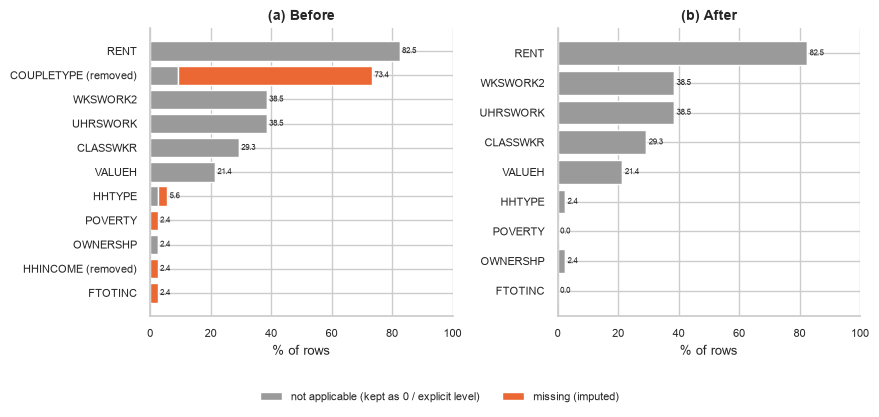

In [85]:
w = miss.year.map(weights)
g = miss.assign(m=miss.pct_missing * w, a=miss.pct_not_applicable * w, w=w).groupby("variable")
agg = pd.DataFrame({"missing": g.m.sum() / g.w.sum(), "na": g.a.sum() / g.w.sum()})
agg["total"] = agg.missing + agg.na
agg = agg[agg.total > 0.05].sort_values("total", ascending=True)
keep_rows = agg[[status.get(v) == "kept" for v in agg.index]]

fig, axes = subplots(1, 2, figsize=(FULL_W, 3.3), sharex=True)
for ax, t, title, show_missing in [(axes[0], agg, "(a) Before", True), (axes[1], keep_rows, "(b) After", False)]:
    y = np.arange(len(t))
    ax.barh(y, t.na, color=GREY, label="not applicable (kept as 0 / explicit level)")
    ax.barh(y, t.missing if show_missing else 0 * t.missing, left=t.na, color=ORANGE, label="missing (imputed)")
    ax.set_yticks(y); ax.set_yticklabels([v + (" (removed)" if status.get(v) == "removed" else "") for v in t.index])
    ax.set(xlabel="% of rows", title=title)
    for yy, (n, m) in enumerate(zip(t.na, t.missing if show_missing else 0 * t.missing)):
        ax.text(n + m + 0.8, yy, f"{n + m:.1f}", va="center", fontsize=6)
axes[1].set_xlim(0, 100)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))   # below the plots: covers no bar
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_fig(fig, "ba01_missing_before_after")

### ba02 — Outliers: income before and after capping (3.2.1)
Capped at mean + 3σ within each year; the boxes and medians do not move, only the extreme tail. No rows are removed.

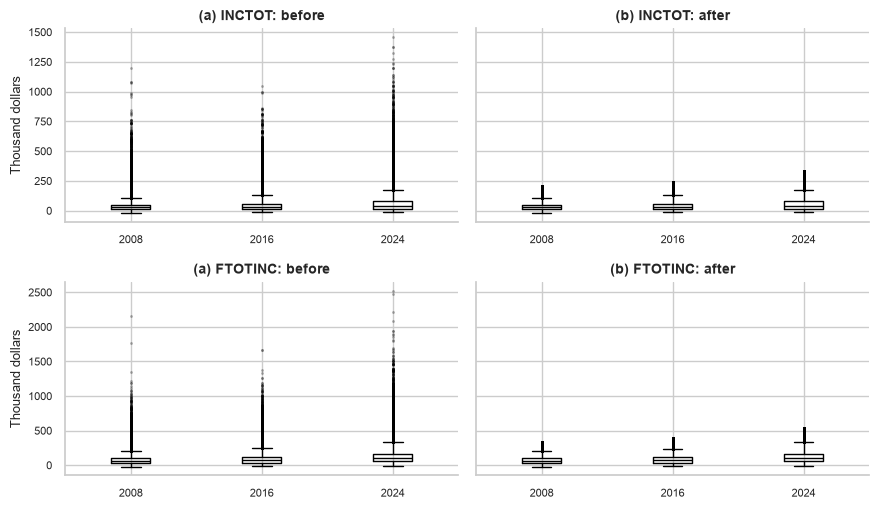

In [86]:
vars2 = [v for v in ["INCTOT", "FTOTINC"] if f"{v}_before" in smp.columns]
fig, axes = subplots(len(vars2), 2, figsize=(FULL_W, 4.2), sharey="row")
for r, var in enumerate(vars2):
    for c, kind in enumerate(["before", "after"]):
        groups = [smp.loc[smp.YEAR == yr, f"{var}_{kind}"].dropna() / 1000 for yr in years]
        ax = axes[r][c]
        ax.boxplot(groups, flierprops={"markersize": 1, "alpha": 0.3}, medianprops={"color": "black"})
        ax.set_xticks(range(1, len(years) + 1)); ax.set_xticklabels(years)
        ax.set(title=f"({'ab'[c]}) {var}: {kind}", ylabel="Thousand dollars" if c == 0 else "")
fig.tight_layout()
save_fig(fig, "ba02_outliers_before_after")

### ba03 — Standardization (3.2.2)
Original units (a) and within-year z-score (b); the zero-income spike is not drawn.

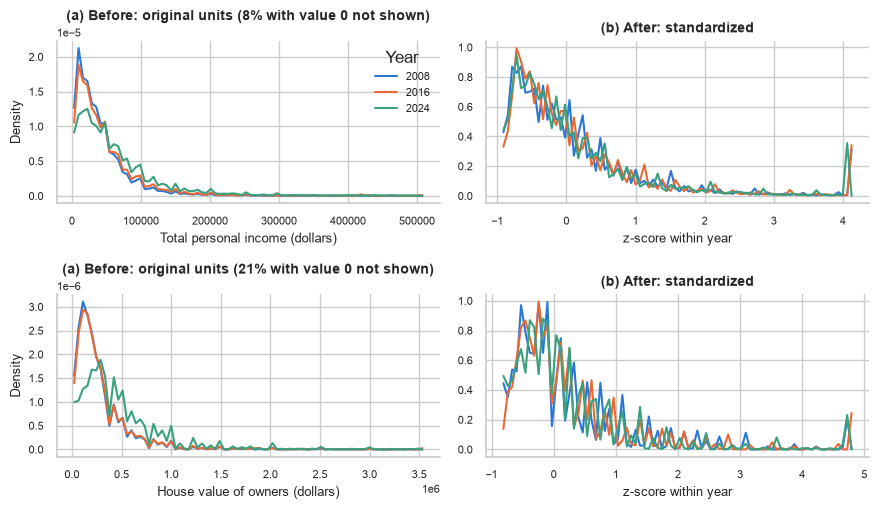

In [87]:
sc = scal.set_index(["variable", "year"])
rows = [("INCTOT", "Total personal income (dollars)"), ("VALUEH", "House value of owners (dollars)")]
rows = [r for r in rows if f"{r[0]}_after" in smp.columns and not smp[f"{r[0]}_after"].isna().all()]
fig, axes = subplots(len(rows), 2, figsize=(FULL_W, 4.2))
for r, (var, label) in enumerate(rows):
    d = smp[(smp[f"{var}_after"] > 0)].copy()
    zero = 100 * (smp[f"{var}_after"] == 0).mean()
    mean = d.YEAR.map(lambda y: sc.loc[(var, y), "mean"]); std = d.YEAR.map(lambda y: sc.loc[(var, y), "std"])
    d["z"] = (d[f"{var}_after"] - mean) / std
    hi = d[f"{var}_before"].quantile(0.995)
    zlo, zhi = d.z.quantile(0.001), d.z.quantile(0.995)
    for yr in years:
        m = d.YEAR == yr
        h, e = np.histogram(d.loc[m, f"{var}_before"].dropna(), bins=80, range=(0, hi), density=True)
        axes[r][0].plot((e[:-1] + e[1:]) / 2, h, color=year_color[yr], label=str(yr))
        hz, ez = np.histogram(d.loc[m, "z"], bins=80, range=(zlo, zhi), density=True)
        axes[r][1].plot((ez[:-1] + ez[1:]) / 2, hz, color=year_color[yr], label=str(yr))
    axes[r][0].set(xlabel=label, ylabel="Density", title=f"(a) Before: original units ({zero:.0f}% with value 0 not shown)")
    axes[r][1].set(xlabel="z-score within year", title="(b) After: standardized")
axes[0][0].legend(title="Year", frameon=False)
fig.tight_layout()
save_fig(fig, "ba03_standardization_before_after")

### ba05 — One-hot columns per variable (3.2.2)
One 0/1 column per level; removed variables are red in (a).

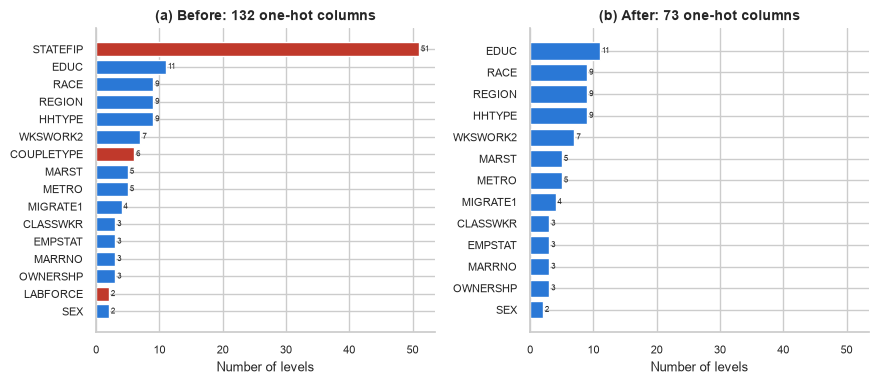

In [88]:
ob = before("onehot_summary"); ob["variable"] = ob.variable.str.replace("_LABEL", "", regex=False)
oa = after("final_onehot_summary")
ob = ob.sort_values("n_levels", ascending=True)
oa = oa.sort_values("n_levels", ascending=True)
fig, axes = subplots(1, 2, figsize=(FULL_W, 3.2), sharex=True)
for ax, t, title in [(axes[0], ob, f"(a) Before: {int(ob.n_levels.sum())} one-hot columns"),
                     (axes[1], oa, f"(b) After: {int(oa.n_levels.sum())} one-hot columns")]:
    cols = [RED if status.get(v) == "removed" else BLUE for v in t.variable]
    ax.barh(t.variable, t.n_levels, color=cols)
    for i, n in enumerate(t.n_levels):
        ax.text(n, i, f" {int(n)}", va="center", fontsize=6)
    ax.set(xlabel="Number of levels", title=title)
fig.tight_layout()
save_fig(fig, "ba05_onehot_levels_before_after")

### ba04 — Funnel: what was removed (3.2.3)
Variables and encoded columns after each step, then the reduced feature set and the PCA components needed for 40 %, 80 % and 90 %.

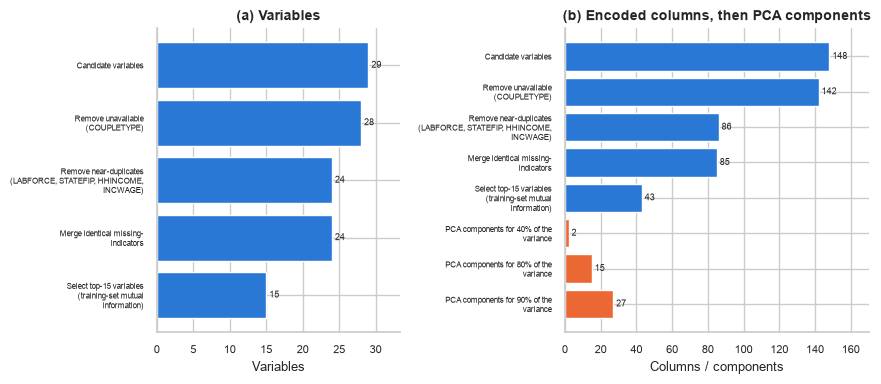

In [89]:
steps = funnel[~funnel.stage.str.startswith("PCA")]
pcas = funnel[funnel.stage.str.startswith("PCA")]
wrap = lambda s: "\n".join(textwrap.wrap(s, 30))
fig, axes = subplots(1, 2, figsize=(FULL_W, 3.2), gridspec_kw={"width_ratios": [1, 1.25]})
y = np.arange(len(steps))
axes[0].barh(y, steps.n_variables, color=BLUE)
axes[0].set_yticks(y); axes[0].set_yticklabels([wrap(s) for s in steps.stage], fontsize=6); axes[0].invert_yaxis()
for i, n in enumerate(steps.n_variables):
    axes[0].text(n, i, f" {int(n)}", va="center", fontsize=6.5)
axes[0].set(xlabel="Variables", title="(a) Variables"); axes[0].set_xlim(0, steps.n_variables.max() * 1.15)
allr = pd.concat([steps, pcas])
y2 = np.arange(len(allr))
axes[1].barh(y2, allr.n_columns, color=[BLUE] * len(steps) + [YEAR_COLORS[1]] * len(pcas))
axes[1].set_yticks(y2)
axes[1].set_yticklabels([wrap(s.replace(" (median over years)", "")) for s in allr.stage], fontsize=6); axes[1].invert_yaxis()
for i, n in enumerate(allr.n_columns):
    axes[1].text(n, i, f" {int(n)}", va="center", fontsize=6.5)
axes[1].set(xlabel="Columns / components", title="(b) Encoded columns, then PCA components")
axes[1].set_xlim(0, allr.n_columns.max() * 1.15)
fig.tight_layout()
save_fig(fig, "ba04_feature_funnel")

### ba06 — Numeric correlation (3.2.3)
Spearman correlation; pairs with |ρ| ≥ 0.9 are outlined. (a) before, (b) after removing one of each pair.

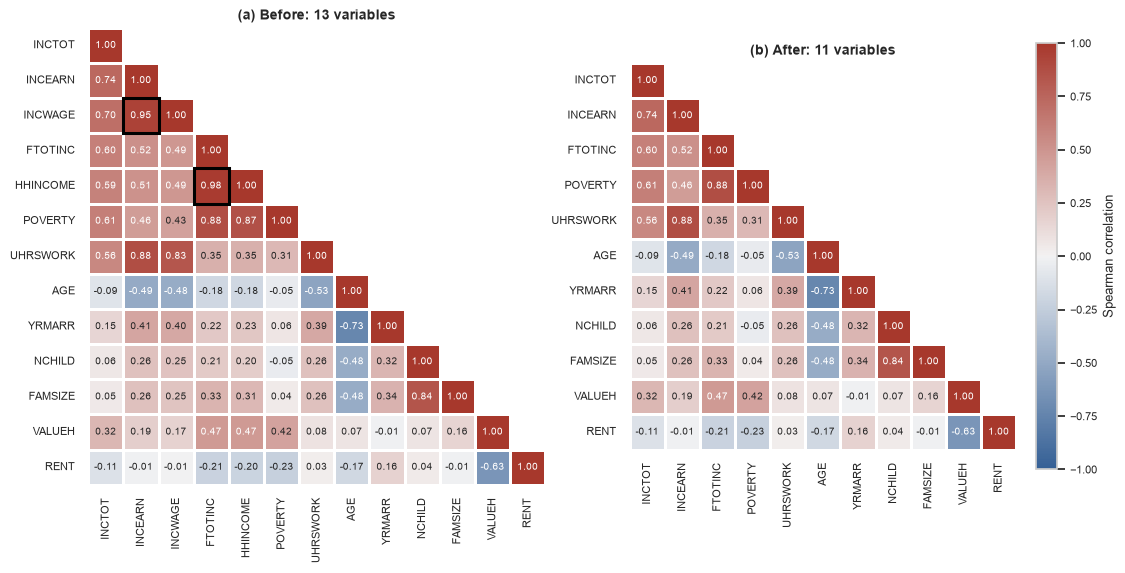

In [90]:
def tri_heatmap(ax, mat, cmap, vmin, vmax, title, thr=0.9, fs=7):
    """Lower-triangle heatmap with the value in every cell; pairs at or above `thr` are outlined."""
    n = len(mat)
    sns.heatmap(mat, mask=np.triu(np.ones((n, n), dtype=bool), k=1), cmap=cmap, vmin=vmin, vmax=vmax, annot=True, fmt=".2f",
                annot_kws={"size": fs}, linewidths=1, linecolor="white", cbar=False, square=True, ax=ax)
    for i in range(n):
        for j in range(i):
            if abs(mat.iat[i, j]) >= thr:
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="black", lw=2.2, zorder=5))
    ax.set_title(title)
    ax.grid(False)
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)


ORDER_NUM = [c for c in ["INCTOT", "INCEARN", "INCWAGE", "FTOTINC", "HHINCOME", "POVERTY", "UHRSWORK", "AGE", "YRMARR",
                         "NCHILD", "FAMSIZE", "VALUEH", "RENT"] if c in sp.index]
nb_ = sp.loc[ORDER_NUM, ORDER_NUM]
na_ = sp.loc[[c for c in ORDER_NUM if c in kept_num], [c for c in ORDER_NUM if c in kept_num]]
CORR_CMAP = sns.diverging_palette(250, 15, s=75, l=40, n=9, center="light", as_cmap=True)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2), gridspec_kw={"width_ratios": [len(nb_), len(na_)]})
tri_heatmap(axes[0], nb_, CORR_CMAP, -1, 1, f"(a) Before: {len(nb_)} variables")
tri_heatmap(axes[1], na_, CORR_CMAP, -1, 1, f"(b) After: {len(na_)} variables")
fig.colorbar(axes[1].collections[0], ax=axes, label="Spearman correlation", fraction=0.022, pad=0.02)
save_fig(fig, "ba06_numeric_correlation_before_after")

### ba07 — Categorical association (3.2.3)
Cramér's V; pairs ≥ 0.9 are outlined. (a) before, (b) after.

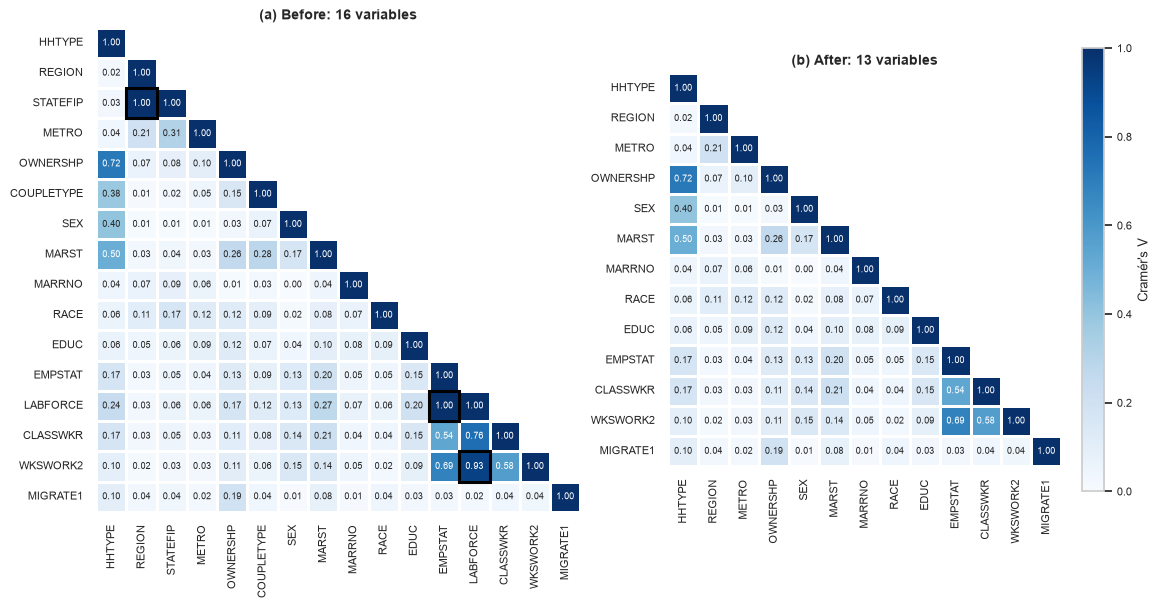

In [91]:
ORDER_CAT = list(cv.index)
cb_ = cv.loc[ORDER_CAT, ORDER_CAT]
ca_ = cv.loc[[c for c in ORDER_CAT if c in kept_cat], [c for c in ORDER_CAT if c in kept_cat]]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6), gridspec_kw={"width_ratios": [len(cb_), len(ca_)]})
tri_heatmap(axes[0], cb_, "Blues", 0, 1, f"(a) Before: {len(cb_)} variables", fs=6.5)
tri_heatmap(axes[1], ca_, "Blues", 0, 1, f"(b) After: {len(ca_)} variables", fs=6.5)
fig.colorbar(axes[1].collections[0], ax=axes, label="Cramér's V", fraction=0.022, pad=0.02)
save_fig(fig, "ba07_cramers_v_before_after")

### ba08 — Mutual information with the target (3.2.3)
Computed on the training rows. Filled: in the reduced set (top-k); hollow: kept but not selected; red: removed.

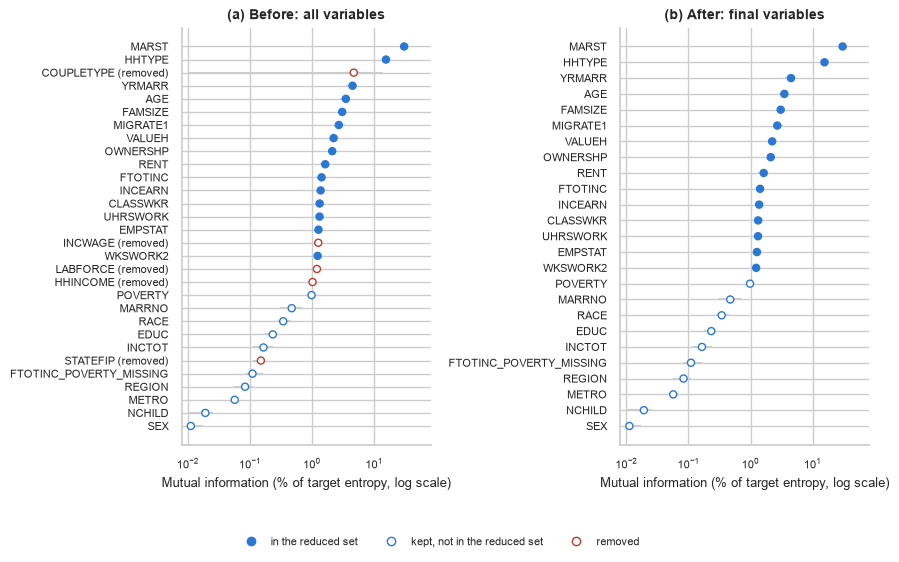

In [92]:
m = mi.groupby("variable").agg(mi=("mi_pct_of_target_entropy", "mean"), lo=("mi_pct_of_target_entropy", "min"),
                               hi=("mi_pct_of_target_entropy", "max"), status=("status", "first"), selected=("selected", "max"))
m[["mi", "lo", "hi"]] = m[["mi", "lo", "hi"]].clip(lower=0.01)
m = m.sort_values("mi")
fig, axes = subplots(1, 2, figsize=(7.16, 4.4), sharex=True)
for ax, t, title in [(axes[0], m, "(a) Before: all variables"), (axes[1], m[m.status == "kept"], "(b) After: final variables")]:
    y = np.arange(len(t))
    color = [RED if s == "removed" else BLUE for s in t.status]
    ax.hlines(y, t.lo, t.hi, color="#cccccc", lw=1.5)
    ax.scatter(t.mi, y, s=26, zorder=3, edgecolors=color, facecolors=[c if (sel and s == "kept") else "white" for c, sel, s in zip(color, t.selected, t.status)])
    ax.set_yticks(y); ax.set_yticklabels([v + (" (removed)" if s == "removed" else "") for v, s in zip(t.index, t.status)])
    ax.set_xscale("log"); ax.set_xlim(0.008, 80)
    ax.set(xlabel="Mutual information (% of target entropy, log scale)", title=title)
fig.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=BLUE, markeredgecolor=BLUE, markersize=6, label="in the reduced set"),
                    Line2D([0], [0], marker="o", color="w", markerfacecolor="white", markeredgecolor=BLUE, markersize=6, label="kept, not in the reduced set"),
                    Line2D([0], [0], marker="o", color="w", markerfacecolor="white", markeredgecolor=RED, markersize=6, label="removed")],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_fig(fig, "ba08_mutual_information_before_after")

### ba09 — PCA: explained variance (3.2.4)
Cumulative variance per year (PCA fitted on the training rows); dots mark 40 %, 80 % and 90 %.

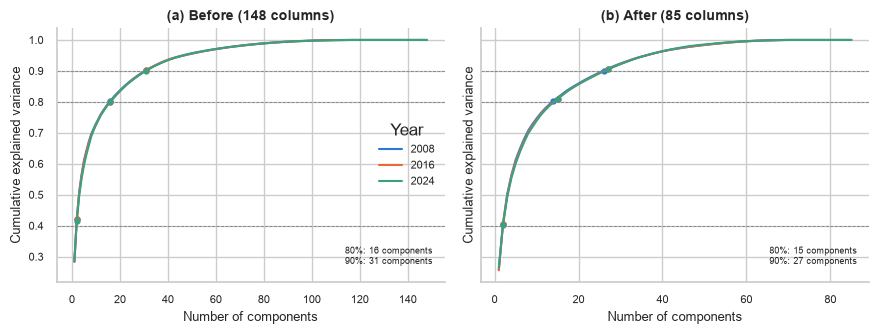

In [93]:
def cum_panel(ax, ev, n_feat, title):
    ks = {0.8: [], 0.9: []}
    for yr, g in ev.groupby("year"):
        g = g.copy(); g["r"] = g.component.str.replace("PC", "").astype(int); g = g.sort_values("r")
        cum = g.cumulative_ratio.astype(float).to_numpy()
        ax.plot(g.r, cum, color=year_color[int(yr)], label=str(int(yr)))
        for t in (0.4, 0.8, 0.9):
            k = int(np.searchsorted(cum, t) + 1)
            ax.plot(k, cum[k - 1], "o", ms=3.5, color=year_color[int(yr)])
            if t in ks: ks[t].append(k)
    for t in (0.4, 0.8, 0.9):
        ax.axhline(t, color="grey", ls="--", lw=0.6)
    ax.text(0.97, 0.06, f"80%: {int(np.median(ks[0.8]))} components\n90%: {int(np.median(ks[0.9]))} components",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=6.5)
    ax.set(xlabel="Number of components", ylabel="Cumulative explained variance", title=f"{title} ({n_feat} columns)")


evb, eva = before("pca_explained_variance"), after("final_pca_explained_variance")
fig, axes = subplots(1, 2, figsize=(FULL_W, 2.8), sharey=True)
cum_panel(axes[0], evb, int(before("pca_summary").n_features.iloc[0]), "(a) Before")
cum_panel(axes[1], eva, int(after("final_pca_summary").n_features.iloc[0]), "(b) After")
axes[0].legend(title="Year", frameon=False, loc="center right")
fig.tight_layout()
save_fig(fig, "ba09_pca_variance_before_after")

### ba10 — PCA: which components separate divorced respondents (3.2.4)
Cohen's d on the test rows, with components fitted on the training rows.

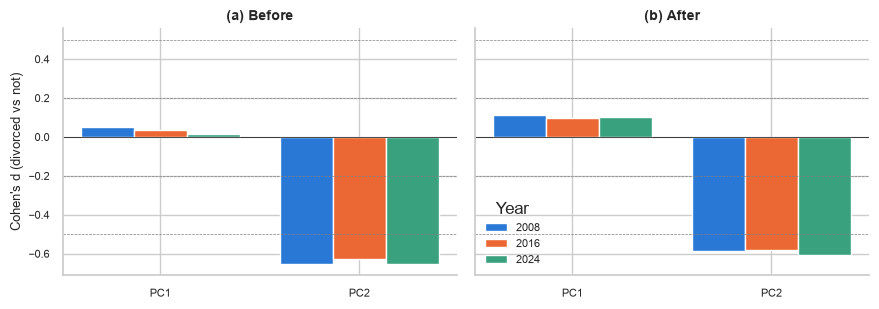

In [94]:
sb, sa = before("pca_class_separation"), after("final_pca_class_separation")
fig, axes = subplots(1, 2, figsize=(FULL_W, 2.6), sharey=True)
for ax, t, title in [(axes[0], sb, "(a) Before"), (axes[1], sa, "(b) After")]:
    p = t.pivot(index="component", columns="year", values="cohens_d").astype(float)
    n = p.shape[1]; wdt = 0.8 / n; pos = np.arange(len(p))
    for i, yr in enumerate(p.columns):
        ax.bar(pos + (i - (n - 1) / 2) * wdt, p[yr], width=wdt, color=year_color[int(yr)], label=str(int(yr)))
    ax.set_xticks(pos); ax.set_xticklabels(p.index)
    ax.axhline(0, color="black", lw=0.5)
    for v in (-0.5, -0.2, 0.2, 0.5):
        ax.axhline(v, color="grey", ls="--", lw=0.5)
    ax.set(title=title)
axes[0].set_ylabel("Cohen's d (divorced vs not)")
axes[1].legend(title="Year", frameon=False)
fig.tight_layout()
save_fig(fig, "ba10_pca_class_separation_before_after")

### ba11 — PCA: PC1 against PC2 on the final features (3.2.4, after only)
A sample of the test rows (red: divorced).

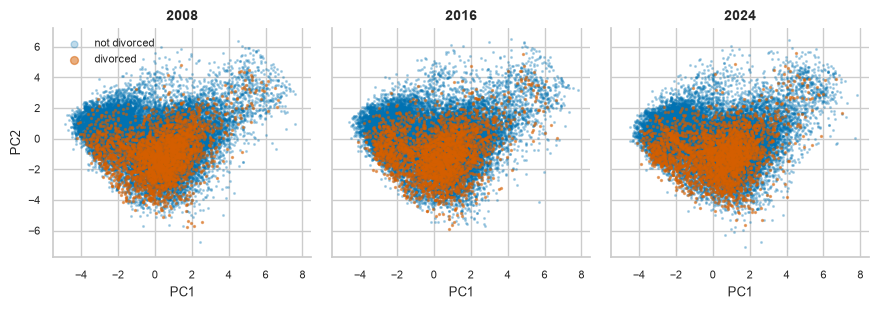

In [95]:
sc_ = after("final_pca_scatter_sample")
fig, axes = subplots(1, len(years), figsize=(FULL_W, 2.6), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, yr in zip(axes, years):
    d = sc_[sc_.year == yr]
    ax.scatter(d[d.DIVINYR == 0].PC1, d[d.DIVINYR == 0].PC2, s=1.5, alpha=0.25, c="#0072B2", label="not divorced")
    ax.scatter(d[d.DIVINYR == 1].PC1, d[d.DIVINYR == 1].PC2, s=2, alpha=0.5, c="#D55E00", label="divorced")
    ax.set(title=str(yr), xlabel="PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(markerscale=4, frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "ba11_pca_scatter_after")

## Clean-up

In [96]:
if not SAVE_OUTPUTS:
    shutil.rmtree(OUT_DIR, ignore_errors=True)
    print("SAVE_OUTPUTS = False: scratch files deleted; nothing was written into the project folder.")
else:
    print(f"Saved in {OUT_DIR}: figures/ (PNG; the 3.1 figures are in figures/eda/) and final_reports/ (result tables; the decision table is final_cleaning_decisions.csv).")

Saved in /Users/artyomborodovitsyn/Desktop/SFU/temp454/divorce-analysis/report_outputs: figures/ (PNG; the 3.1 figures are in figures/eda/) and final_reports/ (result tables; the decision table is final_cleaning_decisions.csv).
